# Phase 2 Legal Named Entity Recognition — Knowledge Distillation

The Phase 2 data files are downloaded directly from the Hugging Face dataset repository (no manual Phase_2_LNER attachment is needed). This notebook distills a trained Phase 2 L-NER teacher into a smaller custom decoder student. It preserves the custom RoPE/RMSNorm/GQA architecture family, byte-level BPE tokenizer, strict character-span evaluation, BIO tagging, character-boundary student head, early stopping, and final submission schema. The default student has 256 hidden dimensions and 6 transformer blocks (versus the teacher/base configuration of 512 dimensions and 15 blocks).

**Important setup:** attach the saved Phase 2 teacher checkpoint (`best_lner_fullft.pt`, `best_lner_lora.pt`, or `best_lner_lorma_plus.pt`) as a Kaggle Dataset, along with the Phase 1 model/tokenizer dataset and Phase 2 L-NER dataset. Set `TEACHER_CHECKPOINT_PATH` in the experiment cell if more than one teacher checkpoint is found. This notebook supports regular full fine-tuning, floating-point LoRA, and LoRMA+ checkpoints; quantized/QLoRA wrappers are not supported.

The student is initialized by shape-aware truncation of selected teacher weights, then trained with a combination of gold BIO supervision and temperature-scaled teacher-logit distillation. BIOES teacher outputs are mapped into BIO student tags. If the teacher checkpoint has no character head, distillation uses the token head and the student character head is trained with gold character labels. A smaller student is not guaranteed to match teacher macro-F1.

## Correctness notes (updated)
- Uses a **BIO** tag scheme consistently for token and character labels.
- The character-boundary head is instantiated, trained with its own loss, used for validation, and used for final inference. It can predict character boundaries inside a byte-level BPE token.
- Strict entity macro-F1 on Fold 2 selects the best checkpoint; early stopping is enabled.
- Predicted spans are not heuristically trimmed for punctuation: exact offsets are preserved for strict evaluation.
- The notebook uses the Phase 1 custom decoder/tokenizer and the Phase 2 Fold 1/Fold 2/Fold 3 data. Run cells from top to bottom.


In [1]:
import os
import random
import json
import time
import zipfile
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import autocast, GradScaler
from tqdm import tqdm
from huggingface_hub import login, hf_hub_download
from kaggle_secrets import UserSecretsClient
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace

# ==========================================
# 1. Setup, Configuration & Authentication
# ==========================================
HF_TOKEN = None
try:
    user_secrets = UserSecretsClient()
    HF_TOKEN = user_secrets.get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    try:
        login(token=HF_TOKEN)
    except Exception as exc:
        print(f"Hugging Face login skipped/failed; local attached assets can still be used ({type(exc).__name__}).")
else:
    print("HF token not found. This notebook expects the Phase 1 model/tokenizer and Phase 2 data attached locally; downloads may require a token.")

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
# TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

PROPORTIONS = {
    "train_supreme_court.json": 0.40,
    "train_high_courts.json": 0.25,
    "train_acts.json": 0.20,
    "train_tribunals.json": 0.15
}

# Hyperparameters
TRAIN_TOKENS = 150_000_000  # Adjust based on your time constraints
VAL_TOKENS = 4_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)

# Custom Model Dimensions (~50M params)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 512
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4 
VOCAB_SIZE = 32000

# Training Optimizations (2x T4 specific)
BATCH_SIZE = 2       # Scaled up for dual GPUs
ACCUMULATION_STEPS = 16 # Effective batch size = 32

# Generation Config
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7
TOP_P = 0.9

# Paths
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-custom-final")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "latest_checkpoint.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
os.makedirs(OUTPUT_DIR, exist_ok=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


CUDA available: True
GPU count: 2


In [2]:
# Phase 1 artifact resolution: choose the model AND tokenizer from the same Kaggle Dataset.
from pathlib import Path
import shutil

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working/cs781_phase1")
WORK_ROOT.mkdir(parents=True, exist_ok=True)
(WORK_ROOT / "legal-custom-final").mkdir(parents=True, exist_ok=True)

# If more than one attached Kaggle Dataset contains both assets, set this to its folder name
# under /kaggle/input (the dataset slug). Example: PHASE1_ASSET_DATASET_SLUG = "my-phase1-model".
PHASE1_ASSET_DATASET_SLUG = None


def _input_dataset_slug(path):
    try:
        relative = path.relative_to(INPUT_ROOT)
        return relative.parts[0] if relative.parts else None
    except ValueError:
        return None


tokenizer_candidates = sorted(p for p in INPUT_ROOT.rglob("custom_bpe_scratch.json") if p.is_file())
model_candidates = sorted(p for p in INPUT_ROOT.rglob("pytorch_model.bin") if p.is_file())

if not tokenizer_candidates:
    raise FileNotFoundError("custom_bpe_scratch.json was not found under /kaggle/input. Attach your Phase 1 model Dataset.")
if not model_candidates:
    raise FileNotFoundError("pytorch_model.bin was not found under /kaggle/input. Attach your Phase 1 model Dataset.")

# Only dataset roots containing both filenames are candidates.
tokenizer_slugs = {_input_dataset_slug(p) for p in tokenizer_candidates}
model_slugs = {_input_dataset_slug(p) for p in model_candidates}
common_slugs = sorted(s for s in tokenizer_slugs.intersection(model_slugs) if s is not None)
if PHASE1_ASSET_DATASET_SLUG is not None:
    common_slugs = [s for s in common_slugs if s == PHASE1_ASSET_DATASET_SLUG]

if len(common_slugs) != 1:
    print("Tokenizer candidates:")
    for p in tokenizer_candidates:
        print(" ", p)
    print("Model candidates:")
    for p in model_candidates:
        print(" ", p)
    raise RuntimeError(
        "Cannot uniquely identify a Phase 1 Dataset containing both the tokenizer and model. "
        "Set PHASE1_ASSET_DATASET_SLUG above to the correct folder name under /kaggle/input."
    )

selected_slug = common_slugs[0]
selected_tokenizers = [p for p in tokenizer_candidates if _input_dataset_slug(p) == selected_slug]
selected_models = [p for p in model_candidates if _input_dataset_slug(p) == selected_slug]
if len(selected_tokenizers) != 1 or len(selected_models) != 1:
    print(f"Multiple asset files exist in Dataset {selected_slug!r}.")
    print("Tokenizers:", *selected_tokenizers, sep="\n  ")
    print("Models:", *selected_models, sep="\n  ")
    raise RuntimeError(
        "There must be exactly one tokenizer and one model checkpoint in the selected dataset root. "
        "Remove duplicates or edit the candidate-selection logic to choose the matching pair explicitly."
    )

tokenizer_src = selected_tokenizers[0]
model_src = selected_models[0]
TOKENIZER_PATH = WORK_ROOT / "custom_bpe_scratch.json"
MODEL_PATH = WORK_ROOT / "legal-custom-final" / "pytorch_model.bin"
shutil.copy2(tokenizer_src, TOKENIZER_PATH)
shutil.copy2(model_src, MODEL_PATH)
print("Selected Phase 1 Dataset:", selected_slug)
print("Tokenizer source:", tokenizer_src)
print("Model source:    ", model_src)
print("Tokenizer copied to:", TOKENIZER_PATH, f"({TOKENIZER_PATH.stat().st_size / 1e6:.2f} MB)")
print("Model copied to:    ", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")


Selected Phase 1 Dataset: datasets
Tokenizer source: /kaggle/input/datasets/kalyankakarapathi/phase11/custom_bpe_scratch.json
Model source:     /kaggle/input/datasets/kalyankakarapathi/phase11/pytorch_model.bin
Tokenizer copied to: /kaggle/working/cs781_phase1/custom_bpe_scratch.json (1.87 MB)
Model copied to:     /kaggle/working/cs781_phase1/legal-custom-final/pytorch_model.bin (239.24 MB)


In [3]:
# Phase 1 pretraining data is intentionally not downloaded here.
# Cell 2 already resolved and copied the pretrained Phase 1 checkpoint and tokenizer.
# Phase 2 training uses only the L-NER folds loaded in the Phase 2 cell below.
data_files = {}
print("Skipping Phase 1 corpus download; using the attached Phase 1 model/tokenizer.")


Skipping Phase 1 corpus download; using the attached Phase 1 model/tokenizer.


In [4]:
# import json
# import os
# import random
# from collections import Counter, defaultdict

# class CustomScratchBPE:
#     def __init__(self, vocab_size, special_tokens=None):
#         self.vocab_size = vocab_size
#         self.special_tokens = special_tokens or ["[UNK]", "[PAD]", "[BOS]", "[EOS]"]
#         self.vocab = {}       
#         self.inv_vocab = {}   
#         self.merges = {}      
        
#     def train(self, text_list):
#         print("Aggregating and filtering word frequencies...")
#         word_freqs = Counter()
        
#         for text in text_list:
#             words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
#             word_freqs.update(words)
            
#         # Drop singletons to save RAM
#         word_freqs = Counter({word: freq for word, freq in word_freqs.items() if freq > 1})
#         print(f"Unique words after filtering singletons: {len(word_freqs):,}")
            
#         unique_chars = set()
#         for word in word_freqs:
#             unique_chars.update(list(word))
            
#         idx = 0
#         for st in self.special_tokens:
#             self.vocab[st] = idx
#             self.inv_vocab[idx] = st
#             idx += 1
            
#         for ch in sorted(list(unique_chars)):
#             self.vocab[ch] = idx
#             self.inv_vocab[idx] = ch
#             idx += 1
            
#         splits = {word: [self.vocab[c] for c in word] for word in word_freqs}
#         target_merges = self.vocab_size - len(self.vocab)
#         print(f"Base character vocab size: {len(self.vocab)}. Target merges: {target_merges}")
        
#         # ---------------------------------------------------------
#         # SPEED OPTIMIZATION: Initial Pair Counts & Inverted Index
#         # ---------------------------------------------------------
#         pair_counts = defaultdict(int)
#         pair_to_words = defaultdict(set)
        
#         for word, freq in word_freqs.items():
#             split = splits[word]
#             for j in range(len(split) - 1):
#                 pair = (split[j], split[j+1])
#                 pair_counts[pair] += freq
#                 pair_to_words[pair].add(word)

#         for i in range(target_merges):
#             if not pair_counts:
#                 break
                
#             best_pair = max(pair_counts, key=pair_counts.get)
#             new_id = idx
#             idx += 1
            
#             self.merges[best_pair] = new_id
#             new_token_str = self.inv_vocab[best_pair[0]] + self.inv_vocab[best_pair[1]]
#             self.vocab[new_token_str] = new_id
#             self.inv_vocab[new_id] = new_token_str
            
#             # ---------------------------------------------------------
#             # FAST INCREMENTAL UPDATE: Only modify words containing best_pair
#             # ---------------------------------------------------------
#             words_to_update = list(pair_to_words.get(best_pair, []))
            
#             del pair_counts[best_pair]
#             if best_pair in pair_to_words:
#                 del pair_to_words[best_pair]
            
#             for word in words_to_update:
#                 split = splits[word]
#                 freq = word_freqs[word]
                
#                 # 1. Remove old pairs from global tracking for this word
#                 for j in range(len(split) - 1):
#                     pair = (split[j], split[j+1])
#                     if pair != best_pair:
#                         pair_counts[pair] -= freq
#                         if pair_counts[pair] <= 0:
#                             del pair_counts[pair]
#                         if word in pair_to_words[pair]:
#                             pair_to_words[pair].remove(word)

#                 # 2. Perform the merge on this word's split
#                 new_split = []
#                 j = 0
#                 while j < len(split):
#                     if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
#                         new_split.append(new_id)
#                         j += 2
#                     else:
#                         new_split.append(split[j])
#                         j += 1
#                 splits[word] = new_split

#                 # 3. Add newly created pairs to global tracking for this word
#                 for j in range(len(new_split) - 1):
#                     pair = (new_split[j], new_split[j+1])
#                     pair_counts[pair] += freq
#                     pair_to_words[pair].add(word)
                
#             if (i + 1) % 500 == 0:
#                 print(f"Completed {i + 1}/{target_merges} merges...")

#     def encode(self, text):
#         words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
#         tokens = []
#         unk_id = self.vocab.get("[UNK]", 0)
        
#         for word in words:
#             split = [self.vocab.get(c, unk_id) for c in word]
#             while len(split) > 1:
#                 min_idx = -1
#                 min_rank = float('inf')
#                 for i in range(len(split) - 1):
#                     pair = (split[i], split[i+1])
#                     if pair in self.merges:
#                         rank = self.merges[pair]
#                         if rank < min_rank:
#                             min_rank = rank
#                             min_idx = i
#                 if min_idx == -1:
#                     break
#                 pair = (split[min_idx], split[min_idx+1])
#                 new_id = self.merges[pair]
#                 split = split[:min_idx] + [new_id] + split[min_idx+2:]
#             tokens.extend(split)
#         return tokens

#     def decode(self, token_ids):
#         text = "".join(self.inv_vocab.get(t, "[UNK]") for t in token_ids)
#         return text.replace("Ġ", " ").strip()

#     def get_vocab_size(self):
#         return len(self.vocab)

#     def save(self, path):
#         serializable_merges = {f"{k[0]},{k[1]}": v for k, v in self.merges.items()}
#         data = {"vocab": self.vocab, "merges": serializable_merges, "special_tokens": self.special_tokens}
#         with open(path, "w", encoding="utf-8") as f:
#             json.dump(data, f, ensure_ascii=False, indent=2)

#     def load(self, path):
#         with open(path, "r", encoding="utf-8") as f:
#             data = json.load(f)
#         self.vocab = data["vocab"]
#         self.inv_vocab = {v: k for k, v in self.vocab.items()}
#         self.special_tokens = data["special_tokens"]
#         self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}

# # ==========================================
# # 2. Load or Train BPE Tokenizer
# # ==========================================
# tokenizer_path = os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json")

# tokenizer = CustomScratchBPE(vocab_size=32000)

# if os.path.exists(tokenizer_path):
#     print(f"Loading existing tokenizer from {tokenizer_path}...")
#     tokenizer.load(tokenizer_path)
#     print(f"Loaded Vocabulary size: {tokenizer.get_vocab_size()}")
# else:
#     print("Streaming subset for tokenizer training...")
#     text_corpus_for_tokenizer = []

#     for filename, filepath in data_files.items():
#         print(f"Adding from {filename}")
#         records = []
        
#         with open(filepath, "r", encoding="utf-8") as f:
#             first_char = f.read(1)
#             f.seek(0)
            
#             if first_char != '[':
#                 for i, line in enumerate(f):
#                     if i > 5000: break
#                     try:
#                         obj = json.loads(line)
#                         if isinstance(obj, dict) and "text" in obj:
#                             records.append(obj)
#                     except:
#                         continue
#             else:
#                 for line in f:
#                     if len(records) >= 2000: break
#                     try:
#                         obj = json.loads(line.strip().strip(','))
#                         if isinstance(obj, dict) and "text" in obj:
#                             records.append(obj)
#                     except:
#                         continue

#         if records:
#             sample_docs = random.sample(records, min(1000, len(records)))
#             text_corpus_for_tokenizer.extend([d["text"] for d in sample_docs if "text" in d])

#     print("Training Custom BPE Tokenizer from scratch (Optimized Incremental)...")
#     tokenizer.train(text_corpus_for_tokenizer)
#     tokenizer.save(tokenizer_path)
#     print(f"Final Vocabulary size: {tokenizer.get_vocab_size()}")

In [5]:
import re
import json
import os
from collections import Counter, defaultdict

def clean_and_filter(text, ascii_threshold=0.85):
    """
    Cleans text and quickly rejects non-English/heavily foreign text.
    """
    if not text or len(text) < 20: 
        return None
        
    ascii_count = sum(1 for c in text if ord(c) < 128)
    if (ascii_count / len(text)) < ascii_threshold:
        return None 

    text = re.sub(r'\s+', ' ', text).strip()
    return text

class CustomByteLevelBPE:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {} 
        
        # Base vocabulary of all 256 individual bytes
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        
        # Reserved Special Tokens
        self.pad_id = 0  

    def train(self, texts, target_vocab_size):
        print("Aggregating byte sequence frequencies...")
        word_freqs = Counter()
        
        # 1. Chunk texts to prevent massive contiguous memory blocks
        for text in texts:
            # Split into words and whitespace blocks to keep sequence lengths small
            chunks = re.findall(r'\S+|\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode("utf-8")] += 1
                
        # 2. Drop singletons to massively save RAM
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f"Unique byte sequences to process: {len(word_freqs):,}")

        # Initialize splits: word -> list of byte integers
        splits = {word: list(word) for word in word_freqs}
        
        # 3. Build fast inverted index
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        num_merges = target_vocab_size - 256
        print(f"Starting {num_merges} merges...")
        
        for i in range(num_merges):
            if not pair_counts:
                break
                
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            
            # Record the merge
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            
            # 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
            words_to_update = list(pair_to_words.get(best_pair, []))
            
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                
                # Remove old pairs associated with this word from global tracking
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)

                # Execute the merge on this word's internal list
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # Add newly formed pairs back to global tracking
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
                    
            self.next_id += 1
            
            if (i + 1) % 1000 == 0:
                print(f"Merge {i + 1}/{num_merges} completed.")
                
        print("BPE Training complete!")

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[(ids[i], ids[i+1])] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        # Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents
        chunks = re.findall(r'\S+|\s+', text)
        final_ids = []
        
        for chunk in chunks:
            ids = list(chunk.encode("utf-8"))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break 
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
            
        return final_ids

    def decode(self, ids):
        b_text = b"".join(self.vocab[idx] for idx in ids if idx != self.pad_id)
        return b_text.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{p[0]},{p[1]}": v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {
            "vocab_size": self.vocab_size,
            "next_id": self.next_id,
            "merges": serializable_merges,
            "vocab": serializable_vocab
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
            
        self.vocab_size = data["vocab_size"]
        self.next_id = data["next_id"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}
        self.vocab = {int(k): bytes(v) for k, v in data["vocab"].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# ==========================================
# Execution Block
# ==========================================
tokenizer_path = os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json")
if not os.path.isfile(tokenizer_path):
    raise FileNotFoundError(
        "Phase 1 tokenizer is missing. Attach the same Kaggle Dataset that contains "
        "pytorch_model.bin and custom_bpe_scratch.json; this notebook does not train a replacement tokenizer."
    )
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(tokenizer_path)
print(f"Loaded the Phase 1 tokenizer from {tokenizer_path}; vocabulary size={tokenizer.get_vocab_size():,}.")


Loaded the Phase 1 tokenizer from /kaggle/working/cs781_phase1/custom_bpe_scratch.json; vocabulary size=32,000.


In [6]:
import gc
gc.collect()

45

In [7]:
# Phase 1 token packing is skipped because the provided pretrained model is loaded in this notebook.
# Phase 2 creates its own L-NER windows/loaders in the final experiment cell.
train_blocks = []
val_blocks = []
print("Skipping Phase 1 token-tensor allocation and block packing.")


Skipping Phase 1 token-tensor allocation and block packing.


In [8]:
# Phase 1 pretraining DataLoaders are not needed for this Phase 2 experiment.
# Phase 2 builds separate train/validation DataLoaders from the annotated L-NER folds.
train_loader = None
val_loader = None
print("Phase 1 DataLoaders skipped; Phase 2 loaders will be created below.")


Phase 1 DataLoaders skipped; Phase 2 loaders will be created below.


MODEL

In [9]:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Apply padding mask for batched inference
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
            
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        
        # QK-Norm layers for stabilization
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        
        # Apply QK-Norm directly after linear projections
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
        q, k = apply_rotary_emb(q, k, freqs_cis)
        
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1),
            attention_mask=attention_mask
        )
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        # Restored separate norm layers for sequential architecture
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        
        # Standard Sequential FFN with SiLU (Swish) instead of GELU
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4, bias=False), 
            nn.SiLU(), 
            nn.Linear(dim * 4, dim, bias=False)
        )
        
    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        # Sequential Residual Architecture
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        
        out = h + self.ffn(self.norm2(h))
        
        return out, new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        
        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        
        h = self.tok_embeddings(tokens)
        new_caches = []
        
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
            
        return self.output(self.norm(h)), new_caches

# ---------------------------------------------
# Re-instantiate the model 
# ---------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

model.to(device)
if torch.cuda.device_count() > 1:
    print(f"Maximizing compute: Using {torch.cuda.device_count()} GPUs with DataParallel.")
    model = nn.DataParallel(model)

Total trainable parameters: 59,665,152
Maximizing compute: Using 2 GPUs with DataParallel.


In [10]:
# Define the path for the plot since it was missing
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
FINAL_MODEL_PATH = os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin")

# ==========================================
# 5. Training Loop with Resume, Plotting, and Bypass
# ==========================================
from torch.optim.lr_scheduler import OneCycleLR

# 1. Check if the final model is already fully trained
if os.path.exists(FINAL_MODEL_PATH):
    print(f"Final model found at {FINAL_MODEL_PATH}! Loading directly and skipping training.")
    checkpoint_data = torch.load(FINAL_MODEL_PATH, map_location=device, weights_only=True)
    
    # Safely load weights whether using DataParallel or not
    if isinstance(model, nn.DataParallel): 
        model.module.load_state_dict(checkpoint_data)
    else: 
        model.load_state_dict(checkpoint_data)

# 2. If no final model exists, run the training pipeline
else:
    print("Final model not found. Starting/Resuming training pipeline...")
    
    optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
    scaler = GradScaler('cuda')

    total_steps = ((len(train_loader) + ACCUMULATION_STEPS - 1) // ACCUMULATION_STEPS) * EPOCHS
    scheduler = OneCycleLR(optimizer, max_lr=5e-4, total_steps=total_steps + 10, pct_start=0.1, anneal_strategy='cos')

    start_epoch, global_step, resume_batch_idx = 0, 0, -1

    # Resume from intermediate checkpoint if it crashed mid-training
    if os.path.exists(CHECKPOINT_PATH):
        print(f"Resuming from mid-training checkpoint: {CHECKPOINT_PATH}")
        checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
        if isinstance(model, nn.DataParallel): model.module.load_state_dict(checkpoint_data['model_state_dict'])
        else: model.load_state_dict(checkpoint_data['model_state_dict'])
        optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
        scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
        if 'scheduler_state_dict' in checkpoint_data: scheduler.load_state_dict(checkpoint_data['scheduler_state_dict'])
        start_epoch, global_step, resume_batch_idx = checkpoint_data['epoch'], checkpoint_data['global_step'], checkpoint_data.get('batch_idx', -1)

    for epoch in range(start_epoch, EPOCHS):
        model.train()
        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
        running_loss = 0.0 
        
        for i, (x, y) in enumerate(progress_bar):
            if epoch == start_epoch and i <= resume_batch_idx: continue
            x, y = x.to(device), y.to(device)

            with autocast('cuda', dtype=torch.float16):
                logits, _ = model(x) 
                # Replaced .view() with .reshape() to prevent non-contiguous memory crashes
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), label_smoothing=0.1) / ACCUMULATION_STEPS
                
            scaler.scale(loss).backward()
            running_loss += loss.item() * ACCUMULATION_STEPS

            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                try: scheduler.step()
                except ValueError: pass
                
                optimizer.zero_grad()
                global_step += 1
                current_train_loss = running_loss / (ACCUMULATION_STEPS if (i + 1) != len(train_loader) else ((i + 1) % ACCUMULATION_STEPS or ACCUMULATION_STEPS))
                running_loss = 0.0 
                
                if global_step % 100 == 0:
                    progress_bar.set_postfix({"LR": f"{scheduler.get_last_lr()[0]:.2e}", "Train": f"{current_train_loss:.4f}"})
                    
                if global_step % 500 == 0:
                    state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                    torch.save({'epoch': epoch, 'batch_idx': i, 'global_step': global_step, 'model_state_dict': state_dict, 'optimizer_state_dict': optimizer.state_dict(), 'scaler_state_dict': scaler.state_dict(), 'scheduler_state_dict': scheduler.state_dict()}, CHECKPOINT_PATH)

    # Save final model after training completes
    os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
    final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
    torch.save(final_state_dict, FINAL_MODEL_PATH)
    print("Training completed successfully! Final model saved.")

Final model found at /kaggle/working/cs781_phase1/legal-custom-final/pytorch_model.bin! Loading directly and skipping training.


In [11]:
# # Define the path for the plot since it was missing
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# # ==========================================
# # 5. Training Loop with Resume & Plotting (With LR Scheduler)
# # ==========================================
# from torch.optim.lr_scheduler import OneCycleLR

# # Increased max_lr to 5e-4 for the OneCycle scheduler (helps escape local minima)
# optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# # NEW: Calculate total steps and initialize the Cosine/Warmup scheduler
# # Add a safety margin (+ 10 steps) to prevent OneCycleLR from overflowing on the final batch
# total_steps = ((len(train_loader) + ACCUMULATION_STEPS - 1) // ACCUMULATION_STEPS) * EPOCHS
# scheduler = OneCycleLR(
#     optimizer, 
#     max_lr=5e-4, 
#     total_steps=total_steps + 10, # <-- Safe buffer prevents the ValueError
#     pct_start=0.1, 
#     anneal_strategy='cos'
# )

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1
# train_steps, train_loss, val_steps, val_loss = [], [], [], []
# LOGGING_INTERVAL = 100

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     # Check for DataParallel when loading
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint_data['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint_data['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
    
#     # NEW: Load scheduler state if it exists in the checkpoint
#     if 'scheduler_state_dict' in checkpoint_data:
#         scheduler.load_state_dict(checkpoint_data['scheduler_state_dict'])
        
#     start_epoch = checkpoint_data['epoch']
#     global_step = checkpoint_data['global_step']
#     resume_batch_idx = checkpoint_data.get('batch_idx', -1)
#     train_loss = checkpoint_data['train_loss']
#     val_loss = checkpoint_data['val_loss']
#     val_steps = checkpoint_data['val_steps']
#     train_steps = checkpoint_data['train_steps']
    
# val_loader_iter = iter(val_loader)
# print("Starting Training...")

# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     running_loss = 0.0  # Tracker for the true accumulated loss
    
#     for i, (x, y) in enumerate(progress_bar):
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)

#         with autocast('cuda', dtype=torch.float16):
#             # CRITICAL FIX: Restored standard causal forward pass. 
#             # The model takes 'x' directly, not 'enc_x' and 'dec_x'.
#             logits, _ = model(x) 
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()
        
#         # Accumulate the unscaled loss of this micro-batch
#         running_loss += loss.item() * ACCUMULATION_STEPS

#         is_last_batch = (i + 1) == len(train_loader)
        
#         if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
#             scaler.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
            
#             # NEW: Step the learning rate scheduler
#             try:
#                 scheduler.step()
#             except ValueError:
#                 pass
            
#             optimizer.zero_grad()
#             global_step += 1
            
#             # Calculate average training loss for this accumulation cycle
#             steps_in_cycle = ACCUMULATION_STEPS if not is_last_batch else ((i + 1) % ACCUMULATION_STEPS or ACCUMULATION_STEPS)
#             current_train_loss = running_loss / steps_in_cycle
#             running_loss = 0.0  # Reset for the next cycle
            
#             if global_step % LOGGING_INTERVAL == 0:
#                 train_steps.append(global_step)
#                 train_loss.append(current_train_loss)
                
#                 model.eval()
#                 with torch.no_grad():
#                     val_loss_accum = 0.0
#                     val_eval_steps = 10  # Evaluate on multiple batches for stability
                    
#                     for _ in range(val_eval_steps):
#                         try:
#                             val_x, val_y = next(val_loader_iter)
#                         except StopIteration:
#                             val_loader_iter = iter(val_loader)
#                             val_x, val_y = next(val_loader_iter)
                            
#                         val_x, val_y = val_x.to(device), val_y.to(device)
                        
#                         with autocast('cuda', dtype=torch.float16):
#                             v_logits, _ = model(val_x)
#                             v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
#                             val_loss_accum += v_loss.item()
                            
#                     avg_v_loss = val_loss_accum / val_eval_steps
                    
#                 val_steps.append(global_step)
#                 val_loss.append(avg_v_loss)
                
#                 model.train()
                
#                 # NEW: Display the dynamically changing Learning Rate in the progress bar
#                 current_lr = scheduler.get_last_lr()[0]
#                 progress_bar.set_postfix({
#                     "LR": f"{current_lr:.2e}",
#                     "Train": f"{current_train_loss:.4f}", 
#                     "Val": f"{avg_v_loss:.4f}"
#                 })
                
#             if global_step % 500 == 0:
#                 # Check for DataParallel when saving checkpoints
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'scheduler_state_dict': scheduler.state_dict(), # NEW: Save scheduler state
#                     'train_steps': train_steps,
#                     'train_loss': train_loss,
#                     'val_steps': val_steps,
#                     'val_loss': val_loss
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# # Check for DataParallel when saving final model
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")#Error

In [12]:
# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# # Check for DataParallel when saving final model
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")

In [13]:
# Phase 1 language-model text generation is intentionally skipped in this Phase 2 notebook.
# The final experiment cell generates L-NER predictions and creates prediction.json/submission.zip.
print("Skipping unrelated Phase 1 text generation.")


Skipping unrelated Phase 1 text generation.


In [14]:
# #fp32 version
# # ==========================================
# # 6. Batched Test Generation & Submission (Pure FP32 + Top-P)
# # ==========================================
# import os
# import json
# import zipfile
# import torch
# import torch.nn.functional as F
# from tqdm import tqdm
# from huggingface_hub import hf_hub_download

# print("Downloading Test file...")
# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO, 
#     filename="Phase_1_Pretraining/Test/test.json", 
#     repo_type="dataset", 
#     token=HF_TOKEN
# )
# with open(test_file_path, "r", encoding="utf-8") as f:
#     test_data = json.load(f)

# # Extract inner model if wrapped in DataParallel
# eval_model = model.module if isinstance(model, nn.DataParallel) else model
# eval_model.eval()

# def generate_batch_custom(prompts, eval_model, tokenizer, device, target_words=128):
#     batch_size = len(prompts)
    
#     encoded_prompts = [tokenizer.encode(p)[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):] for p in prompts]
#     max_len = max(len(p) for p in encoded_prompts)
    
#     pad_id = 0 
#     padded_inputs = []
#     for p in encoded_prompts:
#         pad_len = max_len - len(p)
#         padded_inputs.append([pad_id] * pad_len + p)
        
#     input_tensor = torch.tensor(padded_inputs, dtype=torch.long).to(device)
#     generated_tokens = [[] for _ in range(batch_size)]
    
#     with torch.no_grad():
#         # NO AUTOCAST: Running in pure FP32 guarantees no Infinity/NaN overflows
#         logits, kv_caches = eval_model(input_tensor, start_pos=0)
            
#         next_token_logits = logits[:, -1, :] / TEMPERATURE
#         TOP_P = 0.90
        
#         sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#         cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        
#         sorted_indices_to_remove = cumulative_probs > TOP_P
#         sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#         sorted_indices_to_remove[..., 0] = 0
        
#         indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#         next_token_logits[indices_to_remove] = float('-inf')
        
#         probs = F.softmax(next_token_logits, dim=-1)
        
#         # Absolute safety fallback against rounding errors
#         probs = probs + 1e-10 
#         probs = probs / probs.sum(dim=-1, keepdim=True)
        
#         next_tokens = torch.multinomial(probs, num_samples=1)
        
#         for i in range(batch_size):
#             generated_tokens[i].append(next_tokens[i].item())
            
#         current_token_tensor = next_tokens
#         current_pos = input_tensor.shape[1]
        
#         for _ in range(MAX_GENERATION_TOKENS - 1):
#             if current_pos >= MODEL_CONTEXT_LENGTH:
#                 break
                
#             logits, kv_caches = eval_model(
#                 current_token_tensor, 
#                 start_pos=current_pos, 
#                 kv_caches=kv_caches
#             )
                
#             next_token_logits = logits[:, -1, :] / TEMPERATURE
            
#             sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#             cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            
#             sorted_indices_to_remove = cumulative_probs > TOP_P
#             sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#             sorted_indices_to_remove[..., 0] = 0
            
#             indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#             next_token_logits[indices_to_remove] = float('-inf')
            
#             probs = F.softmax(next_token_logits, dim=-1)
#             probs = probs + 1e-10 
#             probs = probs / probs.sum(dim=-1, keepdim=True)
            
#             next_tokens = torch.multinomial(probs, num_samples=1)
            
#             for i in range(batch_size):
#                 generated_tokens[i].append(next_tokens[i].item())
                
#             current_token_tensor = next_tokens
#             current_pos += 1
            
#     predictions = []
#     for i in range(batch_size):
#         text = tokenizer.decode(generated_tokens[i])
#         words = text.split()[:target_words]
#         predictions.append(" ".join(words))
        
#     return predictions

# # --- Execution ---
# predictions_dict = {}
# GENERATION_BATCH_SIZE = 16 

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")
# print("Generating predictions in batches...")

# for start in tqdm(range(0, total_examples, GENERATION_BATCH_SIZE), desc="Batch Generation"):
#     batch = items[start:start + GENERATION_BATCH_SIZE]
#     batch_ids = [doc_id for doc_id, _ in batch]
#     batch_prompts = [record["text"] for _, record in batch]
    
#     batch_predictions = generate_batch_custom(
#         prompts=batch_prompts,
#         eval_model=eval_model,
#         tokenizer=tokenizer,
#         device=device,
#         target_words=TARGET_GENERATION_WORDS
#     )
    
#     for doc_id, prediction in zip(batch_ids, batch_predictions):
#         predictions_dict[doc_id] = {"text": prediction}

# # Save and Zip
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions_dict, f, ensure_ascii=False, indent=2)

# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Submission created:", SUBMISSION_ZIP)

In [15]:
# def generate_batch_custom(prompts, eval_model, tokenizer, device, target_words=128):
#     batch_size = len(prompts)
    
#     encoded_prompts = [tokenizer.encode(p)[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):] for p in prompts]
#     max_len = max(len(p) for p in encoded_prompts)
    
#     # Left-pad to create a uniform batch tensor
#     pad_id = 0 
#     padded_inputs = []
#     for p in encoded_prompts:
#         pad_len = max_len - len(p)
#         padded_inputs.append([pad_id] * pad_len + p)
        
#     input_tensor = torch.tensor(padded_inputs, dtype=torch.long).to(device)
    
#     generated_tokens = [[] for _ in range(batch_size)]
    
#     with torch.no_grad():
#         with autocast('cuda', dtype=torch.float16):
#             # FIX 1: Remove attention_mask to prevent PyTorch NaN propagation
#             logits, kv_caches = eval_model(
#                 input_tensor, 
#                 start_pos=0
#             )
            
#         # FIX 2: Cast to float32 before dividing by TEMPERATURE to avoid Infinity overflow
#         next_token_logits = logits[:, -1, :].float() / TEMPERATURE
#         TOP_P = 0.90
        
#         sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#         cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        
#         sorted_indices_to_remove = cumulative_probs > TOP_P
#         sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#         sorted_indices_to_remove[..., 0] = 0
        
#         indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#         next_token_logits[indices_to_remove] = float('-inf')
        
#         probs = F.softmax(next_token_logits, dim=-1)
#         next_tokens = torch.multinomial(probs, num_samples=1)
        
#         for i in range(batch_size):
#             generated_tokens[i].append(next_tokens[i].item())
            
#         current_token_tensor = next_tokens
#         current_pos = input_tensor.shape[1]
        
#         # 2. Generation Phase (Token-by-Token)
#         for _ in range(MAX_GENERATION_TOKENS - 1):
#             if current_pos >= MODEL_CONTEXT_LENGTH:
#                 break
                
#             with autocast('cuda', dtype=torch.float16):
#                 logits, kv_caches = eval_model(
#                     current_token_tensor, 
#                     start_pos=current_pos, 
#                     kv_caches=kv_caches
#                 )
                
#             # FIX 2 (Applied here as well): Cast to float32
#             next_token_logits = logits[:, -1, :].float() / TEMPERATURE
            
#             sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#             cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            
#             sorted_indices_to_remove = cumulative_probs > TOP_P
#             sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#             sorted_indices_to_remove[..., 0] = 0
            
#             indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#             next_token_logits[indices_to_remove] = float('-inf')
            
#             probs = F.softmax(next_token_logits, dim=-1)
#             next_tokens = torch.multinomial(probs, num_samples=1)
            
#             for i in range(batch_size):
#                 generated_tokens[i].append(next_tokens[i].item())
                
#             current_token_tensor = next_tokens
#             current_pos += 1
            
#     # Decode and truncate to exact word count on the CPU
#     predictions = []
#     for i in range(batch_size):
#         text = tokenizer.decode(generated_tokens[i])
#         words = text.split()[:target_words]
#         predictions.append(" ".join(words))
        
#     return predictions

# # --- Execution ---
# predictions_dict = {}
# GENERATION_BATCH_SIZE = 16  # Your Dual GPUs can process chunks of 16 instantly

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")
# print("Generating predictions in batches...")

# for start in tqdm(range(0, total_examples, GENERATION_BATCH_SIZE), desc="Batch Generation"):
#     batch = items[start:start + GENERATION_BATCH_SIZE]
#     batch_ids = [doc_id for doc_id, _ in batch]
#     batch_prompts = [record["text"] for _, record in batch]
    
#     batch_predictions = generate_batch_custom(
#         prompts=batch_prompts,
#         eval_model=eval_model,
#         tokenizer=tokenizer,
#         device=device,
#         target_words=TARGET_GENERATION_WORDS
#     )
    
#     for doc_id, prediction in zip(batch_ids, batch_predictions):
#         predictions_dict[doc_id] = {"text": prediction}

# # Save and Zip
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions_dict, f, ensure_ascii=False, indent=2)

# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Submission created:", SUBMISSION_ZIP)

## Phase 2 — Student training with knowledge distillation

The Phase 2 data files are downloaded from Hugging Face automatically; do not attach Phase_2_LNER manually. Kaggle Internet must be ON. If DNS resolution fails, enable Internet in Settings → Session options, restart the session, and rerun.

Prerequisite: first train the full-fine-tuning or LoRMA+ teacher notebook. Export its best `.pt` checkpoint as a Kaggle Dataset and attach that dataset to this notebook. Then set `TEACHER_CHECKPOINT_PATH` in the experiment cell if auto-discovery finds zero or multiple checkpoints. The student is initialized from the teacher and trained with supervised BIO losses plus temperature-scaled token/character distillation.


### Updated diagnostic workflow

This version prints strict per-label precision, recall, F1, TP/FP/FN and gold/prediction counts after Fold 2 inference. It saves `fold2_metrics.json`, `fold2_per_label_metrics.csv`, and `fold2_error_examples.json` under the experiment output directory. It also removes the duplicate punctuation-stripping span cleaner so final inference uses the same exact-boundary policy as validation. Keep the baseline hyperparameters fixed until these diagnostics have been reviewed; tune only against Fold 2, not Fold 3.


Downloaded from Hugging Face: Phase_2_LNER/Train/fold1-text.json -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold1-text.json
Downloaded from Hugging Face: Phase_2_LNER/Train/fold1-gold.json -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold1-gold.json
Downloaded from Hugging Face: Phase_2_LNER/Train/fold2-text.json -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold2-text.json
Downloaded from Hugging Face: Phase_2_LNER/Train/fold2-gold.json -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold2-gold.json
Downloaded from Hugging Face: Phase_2_LNER/Train/labels.txt -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/labels.txt
Downloaded from Hugging Face: Phase_2_LNER/Test/fold3-text.json -> /kaggle/working/hf_phase2_cache/Phase_2_LNER/Test/fold3-text.json
Phase 2 files resolved:
  /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold1-text.json
  /kaggle/working/hf_phase2_cache/Phase_2_LNER/Train/fold1-gold.json
  /kaggle/working/hf_phase2_cache/Phase_

Tokenising Fold 1 train:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 1 train: 747 windows; skipped empty docs: 0


Tokenising Fold 2 validation:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 2 validation: 753 windows; skipped empty docs: 0
Teacher tag scheme: BIO; student tag scheme: BIOES
Teacher loaded: /kaggle/input/datasets/kalyankakarapathi/phase11/best_lner_lora.pt (type=lora)
Teacher hidden size=512, layers=15, tags=25, character head=True
Teacher blocks used for student initialization: [0, 3, 6, 8, 11, 14]
Teacher parameters (decoder + heads): 23,252,786
Student parameters (decoder + heads): 12,564,578 (54.0% of teacher)
BIOES token-tag counts: {'O': 708282, 'B-APP': 295, 'I-APP': 747, 'E-APP': 295, 'S-APP': 68, 'B-RESP': 177, 'I-RESP': 632, 'E-RESP': 177, 'S-RESP': 151, 'B-A.COUNSEL': 106, 'I-A.COUNSEL': 246, 'E-A.COUNSEL': 106, 'S-A.COUNSEL': 10, 'B-R.COUNSEL': 122, 'I-R.COUNSEL': 257, 'E-R.COUNSEL': 122, 'S-R.COUNSEL': 18, 'B-JUDGE': 150, 'I-JUDGE': 521, 'E-JUDGE': 150, 'S-JUDGE': 8, 'B-WIT': 108, 'I-WIT': 168, 'E-WIT': 108, 'S-WIT': 23, 'B-AUTH': 695, 'I-AUTH': 1099, 'E-AUTH': 695, 'S-AUTH': 301, 'B-COURT': 856, 'I-COURT': 1384, 'E-COURT': 856, 'S-COURT': 

KD student epoch 1/20:   0%|          | 0/374 [00:00<?, ?it/s]

... (55 outputs left out)

{
  "epoch": 19,
  "train_loss": 0.2123287088551464,
  "val_combined_loss": 0.6392639555720692,
  "precision": 0.1487603305785124,
  "recall": 0.24011233325532413,
  "micro_f1": 0.1837063563115488,
  "macro_f1": 0.11565631177122836,
  "tp": 1026,
  "fp": 5871,
  "fn": 3247,
  "per_label_f1": {
    "APP": 0.0,
    "RESP": 0.008714596949891067,
    "A.COUNSEL": 0.0,
    "R.COUNSEL": 0.01702127659574468,
    "JUDGE": 0.022123893805309734,
    "WIT": 0.0,
    "AUTH": 0.1470311027332705,
    "COURT": 0.5603799185888738,
    "STAT": 0.24226110363391656,
    "PREC": 0.03355704697986577,
    "DATE": 0.3243835616438356,
    "CASENO": 0.0324032403240324
  },
  "per_label_metrics": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 220,
      "fn": 200
    },
    "RESP": {
      "precision": 0.007434944237918215,
      "recall": 0.010526315789473684,
      "f1": 0.008714596949891067,
      "tp": 2,
      "fp": 267,
      "fn": 188
    },
    "A

KD student epoch 20/20:   0%|          | 0/374 [00:00<?, ?it/s]

Predicting fold2 epoch 20:   0%|          | 0/35 [00:00<?, ?it/s]

{
  "epoch": 20,
  "train_loss": 0.21214786654009538,
  "val_combined_loss": 0.6402427416405362,
  "precision": 0.14954770936679312,
  "recall": 0.23987830564006551,
  "micro_f1": 0.18423654174530424,
  "macro_f1": 0.11589874648231802,
  "tp": 1025,
  "fp": 5829,
  "fn": 3248,
  "per_label_f1": {
    "APP": 0.0,
    "RESP": 0.008771929824561405,
    "A.COUNSEL": 0.0,
    "R.COUNSEL": 0.01705756929637527,
    "JUDGE": 0.022271714922048998,
    "WIT": 0.0,
    "AUTH": 0.14758751182592242,
    "COURT": 0.5619047619047619,
    "STAT": 0.24324324324324323,
    "PREC": 0.0335195530726257,
    "DATE": 0.3238199780461032,
    "CASENO": 0.03260869565217391
  },
  "per_label_metrics": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 215,
      "fn": 200
    },
    "RESP": {
      "precision": 0.007518796992481203,
      "recall": 0.010526315789473684,
      "f1": 0.008771929824561405,
      "tp": 2,
      "fp": 264,
      "fn": 188
    },
  

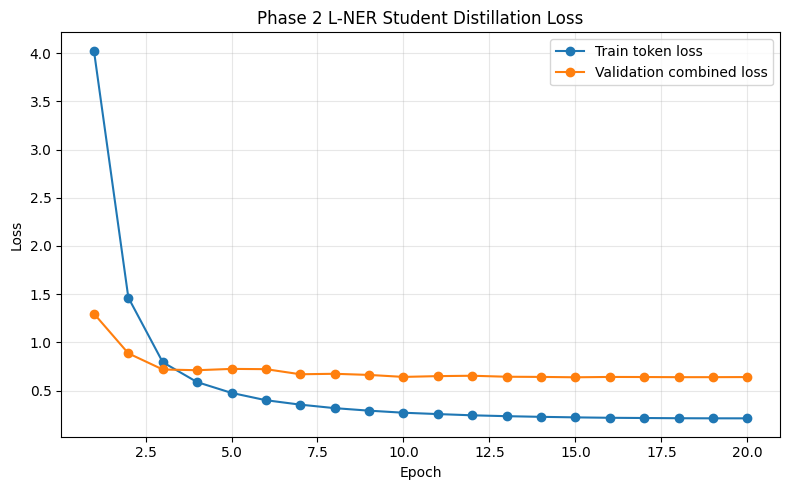

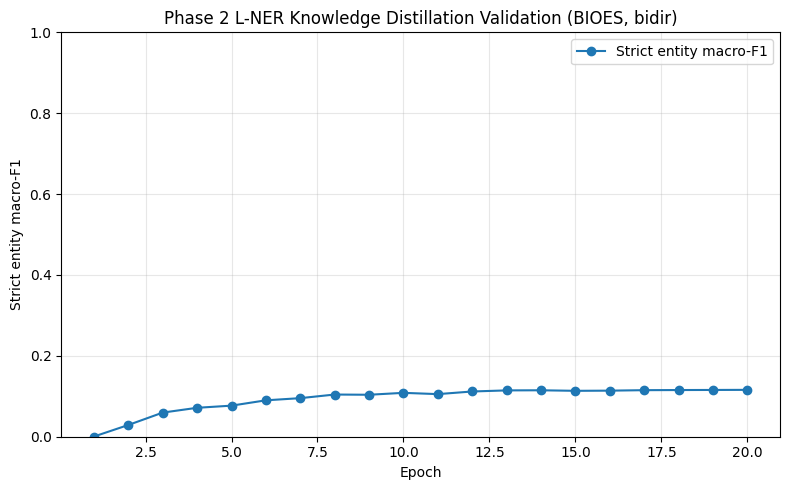

Reloaded best student checkpoint at strict macro-F1=0.1159


Predicting Fold 2 (Validation):   0%|          | 0/35 [00:00<?, ?it/s]


========== FOLD 2 STRICT ENTITY METRICS ==========
Micro precision: 0.149548
Micro recall:    0.239878
Micro F1:        0.184237
Macro F1:        0.115899
Overall TP=1025 FP=5829 FN=3248

Per-label results (strict exact span):
LABEL         PRECISION     RECALL         F1      TP      FP      FN    GOLD    PRED
APP              0.0000     0.0000     0.0000       0     215     200     200     215
RESP             0.0075     0.0105     0.0088       2     264     188     190     266
A.COUNSEL        0.0000     0.0000     0.0000       0     278     125     125     278
R.COUNSEL        0.0108     0.0412     0.0171       4     368      93      97     372
JUDGE            0.0153     0.0410     0.0223       5     322     117     122     327
WIT              0.0000     0.0000     0.0000       0      92     120     120      92
AUTH             0.1324     0.1667     0.1476      78     511     390     468     589
COURT            0.4529     0.7401     0.5619     413     499     145     558     91

Predicting Fold 3 (Test):   0%|          | 0/35 [00:00<?, ?it/s]

Phase 2 complete.
Best checkpoint: /kaggle/working/phase2_lner_decoder_kd_student256x6_bioes_bidir/best_lner_kd_student.pt
Fold 2 Prediction JSON (Local Eval): /kaggle/working/phase2_lner_decoder_kd_student256x6_bioes_bidir/fold2_prediction.json
Fold 3 Prediction JSON: /kaggle/working/phase2_lner_decoder_kd_student256x6_bioes_bidir/prediction.json
Submission ZIP (Upload to Codabench!): /kaggle/working/phase2_lner_decoder_kd_student256x6_bioes_bidir/submission.zip


In [16]:
# Phase 2 L-NER experiment: knowledge distillation from a trained full-fine-tuning teacher to a smaller student.
# The Phase 1 `model` and `tokenizer` are loaded before this cell. A trained Phase 2 teacher checkpoint is required. Supports BIO or BIOES checkpoints from full fine-tuning, LoRA, or LoRMA+; set `TEACHER_CHECKPOINT_PATH` explicitly if auto-detection is ambiguous.

import json
import math
import os
import re
import zipfile
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# -----------------------------
# Experiment settings
# -----------------------------
LNER_MAX_LEN = 1024             # <= Phase 1 model context length (2048 in model2 notebook)
LNER_WINDOW_STRIDE = 512        # overlap windows to reduce context-edge errors
LNER_BATCH_SIZE = 2
LNER_ACCUMULATION_STEPS = 2
LNER_EPOCHS = 20                 # Early stopping selects the best validation macro-F1 checkpoint.
LNER_PATIENCE = 4                # Stop after this many consecutive epochs without a meaningful F1 gain.
LNER_MIN_DELTA = 1e-4
LNER_CHAR_LOSS_WEIGHT = 0.8      # Gold character-level BIO boundary loss.
KD_TEMPERATURE = 2.0
KD_LOSS_WEIGHT = 0.5
KD_CHAR_LOSS_WEIGHT = 0.8
MAX_RELATIVE_CHAR_POSITION = 63
# Compact student architecture and learning rates.
STUDENT_DIM = 256
STUDENT_LAYERS = 6
STUDENT_HEADS = 4
STUDENT_KV_HEADS = 2
STUDENT_LR = 1e-4
NER_HEAD_LR = 5e-4
# Set an explicit path if automatic discovery is ambiguous.
TEACHER_CHECKPOINT_PATH = None  # e.g. "/kaggle/input/my-phase2-teacher/best_lner_fullft.pt"
# Genuine BIOES tags throughout alignment, loss, decoding and checkpointing.
LNER_TAG_SCHEME = "BIOES"
LNER_BIDIRECTIONAL_ATTENTION = True
LNER_SEED = 42
LNER_NUM_WORKERS = 0

random_seed = LNER_SEED
import random
random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Phase 2 file resolution
# -----------------------------
def _find_local_file(filename):
    likely_roots = [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd()]
    seen = set()
    for root in likely_roots:
        if not root.exists() or str(root) in seen:
            continue
        seen.add(str(root))
        direct = root / filename
        if direct.is_file():
            return direct
        # Limit searching to a few known input/working roots; stop at the first exact basename match.
        try:
            for candidate in root.rglob(filename):
                if candidate.is_file():
                    return candidate
        except (PermissionError, OSError):
            pass
    return None


# Hugging Face-only Phase 2 dataset download.
# This intentionally does NOT require manually attaching the Phase_2_LNER dataset in Kaggle.
# It downloads the official files from the configured HF dataset repo and caches them in /kaggle/working.
HF_DATASET_REPO = globals().get("HF_DATASET_REPO", "Exploration-Lab/CS-781-Capstone")
HF_DATASET_REVISION = "main"
HF_PHASE2_CACHE = Path("/kaggle/working/hf_phase2_cache")
HF_PHASE2_CACHE.mkdir(parents=True, exist_ok=True)


def _download_phase2_file_from_hf(filename, subfolder):
    import requests
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry
    from urllib.parse import quote

    relative_path = f"Phase_2_LNER/{subfolder}/{filename}"
    cached_path = HF_PHASE2_CACHE / relative_path
    cached_path.parent.mkdir(parents=True, exist_ok=True)

    # A valid cached file downloaded previously from this HF repository can be reused.
    if cached_path.is_file() and cached_path.stat().st_size > 0:
        print(f"Using Hugging Face cache: {cached_path}")
        return str(cached_path)

    url = (
        f"https://huggingface.co/datasets/{HF_DATASET_REPO}/resolve/"
        f"{HF_DATASET_REVISION}/{quote(relative_path, safe='/')}"
    )
    token = globals().get("HF_TOKEN", None)
    headers = {"Authorization": f"Bearer {token}"} if token else {}

    retry = Retry(
        total=6,
        connect=6,
        read=6,
        status=5,
        backoff_factor=2.0,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(["GET"]),
        respect_retry_after_header=True,
        raise_on_status=False,
    )
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    temp_path = cached_path.with_suffix(cached_path.suffix + ".part")

    try:
        # GET avoids the separate metadata HEAD request that failed in the prior traceback.
        with session.get(url, headers=headers, stream=True, timeout=(20, 180), allow_redirects=True) as response:
            if response.status_code in (401, 403) and token:
                # The dataset should be public; retry anonymously in case the configured token is stale.
                response.close()
                with session.get(url, stream=True, timeout=(20, 180), allow_redirects=True) as public_response:
                    public_response.raise_for_status()
                    with open(temp_path, "wb") as f:
                        for chunk in public_response.iter_content(chunk_size=1024 * 1024):
                            if chunk:
                                f.write(chunk)
            else:
                if response.status_code == 404:
                    raise FileNotFoundError(
                        f"Hugging Face returned HTTP 404 for {url}. Check the repository and file path."
                    )
                response.raise_for_status()
                with open(temp_path, "wb") as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)

        if not temp_path.is_file() or temp_path.stat().st_size == 0:
            raise IOError(f"Hugging Face returned an empty file for {relative_path}")
        os.replace(temp_path, cached_path)
        print(f"Downloaded from Hugging Face: {relative_path} -> {cached_path}")
        return str(cached_path)
    except Exception as exc:
        try:
            if temp_path.exists():
                temp_path.unlink()
        except OSError:
            pass
        message = str(exc)
        dns_failure = any(term in message.lower() for term in (
            "name resolution", "getaddrinfo failed", "name or service not known",
            "temporary failure in name resolution", "nameresolutionerror"
        ))
        if dns_failure:
            raise RuntimeError(
                "Cannot resolve huggingface.co from this Kaggle session. This is a network/DNS "
                "problem, not a model or dataset-code problem. In the Kaggle notebook, open the "
                "right-side Settings pane -> Session options -> turn Internet ON, restart the "
                "session, and run again. If the Internet option is missing, verify your Kaggle "
                "account/phone at https://www.kaggle.com/settings."
            ) from exc
        raise RuntimeError(
            f"Could not download {relative_path} from Hugging Face ({url}). "
            f"Check Kaggle Internet access and repository access. Original error: {type(exc).__name__}: {exc}"
        ) from exc
    finally:
        session.close()


def phase2_path(filename, subfolder):
    return _download_phase2_file_from_hf(filename, subfolder)


FOLD1_TEXT_PATH = phase2_path("fold1-text.json", "Train")
FOLD1_GOLD_PATH = phase2_path("fold1-gold.json", "Train")
FOLD2_TEXT_PATH = phase2_path("fold2-text.json", "Train")
FOLD2_GOLD_PATH = phase2_path("fold2-gold.json", "Train")
LABELS_PATH = phase2_path("labels.txt", "Train")
FOLD3_TEXT_PATH = phase2_path("fold3-text.json", "Test")
print("Phase 2 files resolved:", FOLD1_TEXT_PATH, FOLD1_GOLD_PATH, FOLD2_TEXT_PATH, FOLD2_GOLD_PATH, LABELS_PATH, FOLD3_TEXT_PATH, sep="\n  ")

# -----------------------------
# Read Phase 2 JSON formats
# -----------------------------
def read_json_or_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = f.read()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        rows = []
        for line_no, line in enumerate(raw.splitlines(), 1):
            line = line.strip().rstrip(",")
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_no}") from exc
        return rows


def _first_present(record, keys, default=None):
    for key in keys:
        if key in record:
            return record[key]
    return default


def normalise_documents(raw):
    """Return {str(document_id): document_text}; supports the stated ID -> text layout."""
    if isinstance(raw, dict):
        for container_key in ("documents", "data", "docs", "items"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_documents(raw[container_key])
        docs = {}
        for key, value in raw.items():
            if isinstance(value, str):
                docs[str(key)] = value
            elif isinstance(value, dict):
                text = _first_present(value, ("text", "document", "content", "document_text"))
                doc_id = _first_present(value, ("id", "doc_id", "document_id", "docid"), key)
                if isinstance(text, str):
                    docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document text. Expected a document-ID-to-text JSON object or records with id/text fields.")
        return docs
    if isinstance(raw, list):
        docs = {}
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("id", "doc_id", "document_id", "docid", "documentId"))
            text = _first_present(row, ("text", "document", "content", "document_text"))
            if doc_id is not None and isinstance(text, str):
                docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document ID/text records in the JSON list.")
        return docs
    raise ValueError(f"Unsupported document JSON root type: {type(raw).__name__}")


# def normalise_entity(entity):
#     if not isinstance(entity, dict):
#         return None
#     start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
#     end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
#     label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
#     text = _first_present(entity, ("text", "entity_text", "surface"), "")
#     if start is None or end is None or label is None:
#         return None
#     start, end = int(start), int(end)
#     if end <= start:
#         return None
#     return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}

def normalise_entity(entity):
    # Fix: Handle the official Capstone list format [start, end, label, (optional text)]
    if isinstance(entity, (list, tuple)) and len(entity) >= 3:
        start, end, label = int(entity[0]), int(entity[1]), str(entity[2]).strip()
        text = str(entity[3]) if len(entity) > 3 else ""
        if end <= start:
            return None
        return {"start": start, "end": end, "label": label, "text": text}
        
    # Fallback for dictionary formats
    if not isinstance(entity, dict):
        return None
        
    start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
    end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
    label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
    text = _first_present(entity, ("text", "entity_text", "surface"), "")
    
    if start is None or end is None or label is None:
        return None
        
    start, end = int(start), int(end)
    if end <= start:
        return None
        
    return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}


def normalise_gold(raw):
    """Return {str(document_id): [normalized entity dicts]} for document-keyed or record-list JSON."""
    if isinstance(raw, dict):
        for container_key in ("annotations", "entities_by_document", "data", "documents", "records"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_gold(raw[container_key])
        out = {}
        for doc_id, value in raw.items():
            if isinstance(value, list):
                ents = [normalise_entity(e) for e in value]
            elif isinstance(value, dict):
                embedded = _first_present(value, ("entities", "annotations", "spans"))
                if isinstance(embedded, list):
                    ents = [normalise_entity(e) for e in embedded]
                elif _first_present(value, ("start", "start_offset", "start_char")) is not None:
                    ent = normalise_entity(value)
                    record_id = _first_present(value, ("doc_id", "document_id", "docid", "id"), doc_id)
                    out.setdefault(str(record_id), [])
                    if ent is not None:
                        out[str(record_id)].append(ent)
                    continue
                else:
                    continue
            else:
                continue
            out[str(doc_id)] = [e for e in ents if e is not None]
        if not out:
            raise ValueError("Could not parse gold annotations. Expected a document-ID-to-entity-list mapping.")
        return out
    if isinstance(raw, list):
        out = defaultdict(list)
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("doc_id", "document_id", "docid", "documentId", "id"))
            embedded = _first_present(row, ("entities", "annotations", "spans"))
            if doc_id is not None and isinstance(embedded, list):
                out[str(doc_id)].extend(e for e in (normalise_entity(x) for x in embedded) if e is not None)
                continue
            ent = normalise_entity(row)
            if doc_id is not None and ent is not None:
                out[str(doc_id)].append(ent)
        if not out:
            raise ValueError("Could not parse gold records from JSON list.")
        return dict(out)
    raise ValueError(f"Unsupported gold JSON root type: {type(raw).__name__}")


fold1_docs = normalise_documents(read_json_or_jsonl(FOLD1_TEXT_PATH))
fold1_gold = normalise_gold(read_json_or_jsonl(FOLD1_GOLD_PATH))
fold2_docs = normalise_documents(read_json_or_jsonl(FOLD2_TEXT_PATH))
fold2_gold = normalise_gold(read_json_or_jsonl(FOLD2_GOLD_PATH))
test_docs = normalise_documents(read_json_or_jsonl(FOLD3_TEXT_PATH))
with open(LABELS_PATH, "r", encoding="utf-8") as f:
    ENTITY_LABELS = [line.strip() for line in f if line.strip()]
# Handle a leading UTF-8 BOM and duplicate blank/duplicate label lines defensively.
ENTITY_LABELS = list(dict.fromkeys(label.lstrip("\ufeff").strip() for label in ENTITY_LABELS if label.strip()))
if not ENTITY_LABELS:
    raise ValueError("labels.txt is empty; cannot construct the entity classifier.")

print(f"Fold 1: {len(fold1_docs)} documents; {sum(len(fold1_gold.get(k, [])) for k in fold1_docs)} entities")
print(f"Fold 2: {len(fold2_docs)} documents; {sum(len(fold2_gold.get(k, [])) for k in fold2_docs)} entities")
print(f"Test:   {len(test_docs)} documents")
print("Entity labels:", ENTITY_LABELS)

# -----------------------------
# Custom byte-level BPE encoder with character offsets
# -----------------------------
def encode_with_character_offsets(tokenizer, text, verify_parity=False):
    """Mirror CustomByteLevelBPE.encode() exactly while tracking Unicode character spans.

    The Phase 1 tokenizer is byte-level. Each UTF-8 byte initially maps to the Unicode
    character that generated it; merged byte tokens combine those spans. End offsets are
    exclusive, matching the Phase 2 character-span annotation convention.
    """
    all_ids, all_offsets = [], []
    if not text:
        return all_ids, all_offsets

    for match in re.finditer(r"\S+|\s+", text):
        chunk = match.group(0)
        ids = list(chunk.encode("utf-8"))
        spans = []
        absolute_char = match.start()
        for local_char, ch in enumerate(chunk):
            char_span = (absolute_char + local_char, absolute_char + local_char + 1)
            spans.extend([char_span] * len(ch.encode("utf-8")))

        # Same greedy merge priority as CustomByteLevelBPE.encode(): lowest merge ID first.
        while len(ids) >= 2:
            eligible = []
            for i in range(len(ids) - 1):
                pair = (ids[i], ids[i + 1])
                if pair in tokenizer.merges:
                    eligible.append((tokenizer.merges[pair], i, pair))
            if not eligible:
                break
            merge_id, _, pair = min(eligible, key=lambda x: (x[0], x[1]))

            new_ids, new_spans = [], []
            i = 0
            while i < len(ids):
                if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
                    new_ids.append(merge_id)
                    new_spans.append((spans[i][0], max(spans[i][1], spans[i + 1][1])))
                    i += 2
                else:
                    new_ids.append(ids[i])
                    new_spans.append(spans[i])
                    i += 1
            ids, spans = new_ids, new_spans

        all_ids.extend(ids)
        all_offsets.extend(spans)

    # Optional parity check against the notebook's original tokenizer implementation.
    # Run this on a representative document once; repeating it for every document doubles
    # the tokenizer work and can be costly for a custom BPE implementation.
    if verify_parity:
        original_ids = tokenizer.encode(text)
        if all_ids != original_ids:
            raise RuntimeError(
                "Offset-aware BPE differs from tokenizer.encode() for this text. "
                "Check the custom tokenizer's merge implementation before training."
            )
    return all_ids, all_offsets


# One-time parity check: avoid running the original tokenizer a second time for every document.
_parity_sample = next(iter(fold1_docs.values()), "")
if _parity_sample:
    _parity_ids, _parity_offsets = encode_with_character_offsets(tokenizer, _parity_sample, verify_parity=True)
    assert len(_parity_ids) == len(_parity_offsets)
    print("Offset-aware BPE parity check passed on one fold-1 document.")


# -----------------------------
# Data, label, offset and token-boundary audit
# -----------------------------
def audit_lner_split(documents, gold_by_doc, split_name):
    from collections import Counter
    label_counts = Counter()
    unknown_labels = Counter()
    invalid_offsets = []
    text_mismatches = []
    all_spans = defaultdict(list)
    total_entities = 0

    print(f"\n{'=' * 16} {split_name} AUDIT {'=' * 16}")
    print("Documents:", len(documents), "| gold document IDs:", len(gold_by_doc))
    missing_text_ids = sorted(set(gold_by_doc) - set(documents))
    print("Gold IDs without corresponding text:", len(missing_text_ids))
    if missing_text_ids:
        print("Examples:", missing_text_ids[:10])

    for doc_id, entities in gold_by_doc.items():
        text = documents.get(str(doc_id))
        if text is None:
            continue
        for entity in entities:
            total_entities += 1
            label = str(entity.get("label", "")).strip()
            label_counts[label] += 1
            if label not in ENTITY_LABELS:
                unknown_labels[label] += 1
            try:
                start, end = int(entity["start"]), int(entity["end"])
            except (KeyError, TypeError, ValueError):
                invalid_offsets.append((doc_id, entity))
                continue
            if start < 0 or end <= start or end > len(text):
                invalid_offsets.append((doc_id, start, end, len(text)))
                continue
            all_spans[str(doc_id)].append((start, end, label))
            annotated_text = str(entity.get("text", ""))
            if annotated_text and text[start:end] != annotated_text:
                text_mismatches.append((str(doc_id), start, end, annotated_text[:80], text[start:end][:80]))

    overlap_examples = []
    overlap_pairs = 0
    for doc_id, spans in all_spans.items():
        spans.sort(key=lambda x: (x[0], x[1]))
        for i, left in enumerate(spans):
            for right in spans[i + 1:]:
                if right[0] >= left[1]:
                    break
                overlap_pairs += 1
                if len(overlap_examples) < 10:
                    overlap_examples.append((doc_id, left, right))

    print("Entities:", total_entities)
    print("Entities by label:")
    for label, count in label_counts.most_common():
        print(f"  {label:30s} {count:8d}")
    print("Unknown labels:", dict(unknown_labels))
    print("Invalid offsets:", len(invalid_offsets), "| text-slice mismatches:", len(text_mismatches))
    print("Overlapping entity pairs:", overlap_pairs)
    if text_mismatches:
        print("Text-slice mismatch examples (doc, start, end, annotation text, source slice):")
        for row in text_mismatches[:5]:
            print(" ", row)

    # A flat BIO sequence cannot represent overlapping/nested entities, and invalid
    # labels/offsets must not be silently dropped during preprocessing.
    if missing_text_ids or unknown_labels or invalid_offsets or overlap_pairs:
        raise ValueError(
            f"{split_name} annotations need fixing before training: gold IDs without text={len(missing_text_ids)}, "
            f"unknown labels={sum(unknown_labels.values())}, invalid offsets={len(invalid_offsets)}, "
            f"overlap pairs={overlap_pairs}. See audit output above."
        )

    # Exact entity spans can only be reconstructed from this token head when both character
    # boundaries coincide with token boundaries. Quantify that limitation on a small sample.
    candidates = [doc_id for doc_id in documents if gold_by_doc.get(str(doc_id)) and len(documents[doc_id]) <= 20000]
    candidates.sort(key=lambda did: (len(documents[did]), str(did)))
    # Spread the sample across the candidate list rather than only taking the shortest documents.
    if len(candidates) > 12:
        positions = [round(i * (len(candidates) - 1) / 11) for i in range(12)]
        sample_ids = [candidates[i] for i in positions]
    else:
        sample_ids = candidates
    total_sampled = start_aligned = end_aligned = both_aligned = 0
    for doc_id in sample_ids:
        text = documents[doc_id]
        _, offsets = encode_with_character_offsets(tokenizer, text)
        token_starts = {a for a, b in offsets if b > a}
        token_ends = {b for a, b in offsets if b > a}
        for entity in gold_by_doc.get(str(doc_id), []):
            a, b = int(entity["start"]), int(entity["end"])
            total_sampled += 1
            has_start, has_end = a in token_starts, b in token_ends
            start_aligned += int(has_start)
            end_aligned += int(has_end)
            both_aligned += int(has_start and has_end)
    if total_sampled:
        print(f"Token-boundary sample: {total_sampled} entities")
        print(f"  start aligned: {start_aligned / total_sampled:.1%}")
        print(f"  end aligned:   {end_aligned / total_sampled:.1%}")
        print(f"  both aligned (necessary for exact boundary using this head): {both_aligned / total_sampled:.1%}")
        if both_aligned / total_sampled < 0.80:
            print("WARNING: many gold entity boundaries fall inside BPE tokens. A token-only BIO head cannot predict those exact character boundaries; the trained character-level boundary head below is designed to reduce this limitation (it does not guarantee better F1).")
    else:
        print("No annotated short documents available for token-boundary sampling.")


audit_lner_split(fold1_docs, fold1_gold, "FOLD 1 TRAIN")
audit_lner_split(fold2_docs, fold2_gold, "FOLD 2 VALIDATION")


# -----------------------------
# Character spans -> BIOES tags for token and character heads.
# -----------------------------
if LNER_TAG_SCHEME != "BIOES":
    raise ValueError("This experiment is configured for BIOES tags.")
TAG_NAMES = ["O"]
for _label in ENTITY_LABELS:
    TAG_NAMES.extend((f"B-{_label}", f"I-{_label}", f"E-{_label}", f"S-{_label}"))
TAG_TO_ID = {tag: idx for idx, tag in enumerate(TAG_NAMES)}
ID_TO_TAG = {idx: tag for tag, idx in TAG_TO_ID.items()}
IGNORE_INDEX = -100


def normalise_entity_spans(entities, text_length):
    """Validate flat entity spans; reject invalid offsets, unknown labels, and overlaps."""
    result = []
    for entity in entities:
        start = int(entity["start"])
        end = int(entity["end"])
        label = str(entity["label"]).strip()
        if label not in ENTITY_LABELS:
            raise ValueError(f"Unknown entity label {label!r}; labels.txt contains {ENTITY_LABELS}")
        if start < 0 or end <= start or end > text_length:
            raise ValueError(f"Invalid entity offsets {(start, end)} for text length {text_length}")
        result.append((start, end, label))
    result.sort(key=lambda item: (item[0], item[1]))
    for left, right in zip(result, result[1:]):
        if right[0] < left[1]:
            raise ValueError(
                f"Overlapping/nested annotations are not supported by the current flat {LNER_TAG_SCHEME} head: "
                f"{left} and {right}. Use a span-based head for this split."
            )
    return result


def align_offsets_to_bioes(offsets, entities, text_length):
    """Align spans to fully contained tokens; ignore tokens crossing entity boundaries."""
    entity_spans = normalise_entity_spans(entities, text_length)
    tag_strings = ["O"] * len(offsets)
    ignore = [False] * len(offsets)
    contained_by_entity = [[] for _ in entity_spans]
    entity_cursor = 0
    for token_i, (tok_start, tok_end) in enumerate(offsets):
        if tok_end <= tok_start:
            ignore[token_i] = True
            continue
        while entity_cursor < len(entity_spans) and entity_spans[entity_cursor][1] <= tok_start:
            entity_cursor += 1
        overlaps = []
        j = entity_cursor
        while j < len(entity_spans) and entity_spans[j][0] < tok_end:
            ent_start, ent_end, _ = entity_spans[j]
            if max(tok_start, ent_start) < min(tok_end, ent_end):
                overlaps.append(j)
            j += 1
        if len(overlaps) > 1:
            ignore[token_i] = True
        elif overlaps:
            ent_start, ent_end, _ = entity_spans[overlaps[0]]
            if tok_start >= ent_start and tok_end <= ent_end:
                contained_by_entity[overlaps[0]].append(token_i)
            else:
                ignore[token_i] = True

    for entity_index, token_indices in enumerate(contained_by_entity):
        if not token_indices:
            continue
        label = entity_spans[entity_index][2]
        # Keep the original sequence positions: ignored partial tokens split trainable runs.
        runs = []
        current = []
        for token_i in token_indices:
            if current and token_i != current[-1] + 1:
                runs.append(current)
                current = []
            current.append(token_i)
        if current:
            runs.append(current)
        for run in runs:
            if len(run) == 1:
                tag_strings[run[0]] = f"S-{label}"
            else:
                tag_strings[run[0]] = f"B-{label}"
                for token_i in run[1:-1]:
                    tag_strings[token_i] = f"I-{label}"
                tag_strings[run[-1]] = f"E-{label}"

    return [IGNORE_INDEX if ignore[i] else TAG_TO_ID[tag_strings[i]] for i in range(len(offsets))]


def make_window_starts(n_tokens, max_len=LNER_MAX_LEN, stride=LNER_WINDOW_STRIDE):
    if n_tokens <= 0:
        return []
    if n_tokens <= max_len:
        return [0]
    stride = min(max(1, stride), max_len)
    return list(range(0, n_tokens, stride))


def fix_bioes_window_edges(label_ids):
    """Repair BIOES sequences clipped by either edge, ignoring zero-offset tokens."""
    result = list(label_ids)
    valid = [i for i, tag_id in enumerate(result) if tag_id != IGNORE_INDEX]
    if not valid:
        return result
    first_i, last_i = valid[0], valid[-1]

    # A left-edge I/E means this window starts inside an entity. Convert the visible
    # fragment's first tag to B (or S for a one-position fragment).
    first = ID_TO_TAG[int(result[first_i])]
    if first.startswith(("I-", "E-")):
        label = first.split("-", 1)[1]
        run = [first_i]
        j = first_i + 1
        while j <= last_i and result[j] != IGNORE_INDEX:
            tag = ID_TO_TAG[int(result[j])]
            if tag in (f"I-{label}", f"E-{label}"):
                run.append(j)
                if tag == f"E-{label}":
                    break
                j += 1
            else:
                break
        if len(run) == 1:
            result[first_i] = TAG_TO_ID[f"S-{label}"]
        else:
            result[first_i] = TAG_TO_ID[f"B-{label}"]

    # A final B/I means the entity continues beyond the right edge. Close the
    # visible fragment with S or E while preserving its type.
    last = ID_TO_TAG[int(result[last_i])]
    if last.startswith(("B-", "I-")):
        label = last.split("-", 1)[1]
        run_start = last_i
        j = last_i - 1
        while j >= first_i and result[j] != IGNORE_INDEX:
            tag = ID_TO_TAG[int(result[j])]
            if tag in (f"B-{label}", f"I-{label}"):
                run_start = j
                j -= 1
            else:
                break
        if run_start == last_i:
            result[last_i] = TAG_TO_ID[f"S-{label}"]
        else:
            result[run_start] = TAG_TO_ID[f"B-{label}"]
            for k in range(run_start + 1, last_i):
                if result[k] != IGNORE_INDEX and ID_TO_TAG[int(result[k])] in (f"B-{label}", f"I-{label}"):
                    result[k] = TAG_TO_ID[f"I-{label}"]
            result[last_i] = TAG_TO_ID[f"E-{label}"]
    return result


def character_bioes_labels(entities, char_start, char_end, text_length):
    """Character-level BIOES labels; slice and repair window-clipped entity fragments."""
    full_tags = ["O"] * max(0, text_length)
    for ent_start, ent_end, label in normalise_entity_spans(entities, text_length):
        length = ent_end - ent_start
        if length == 1:
            full_tags[ent_start] = f"S-{label}"
        else:
            full_tags[ent_start] = f"B-{label}"
            for pos in range(ent_start + 1, ent_end - 1):
                full_tags[pos] = f"I-{label}"
            full_tags[ent_end - 1] = f"E-{label}"
    lo, hi = max(0, int(char_start)), min(int(char_end), text_length)
    sliced = [TAG_TO_ID[tag] for tag in full_tags[lo:hi]]
    return fix_bioes_window_edges(sliced)


def build_training_windows(documents, gold_by_doc, split_name):
    windows = []
    skipped_empty = 0
    for doc_id, text in tqdm(documents.items(), desc=f"Tokenising {split_name}"):
        token_ids, offsets = encode_with_character_offsets(tokenizer, text)
        if not token_ids:
            skipped_empty += 1
            continue
        entities = gold_by_doc.get(str(doc_id), [])
        labels = align_offsets_to_bioes(offsets, entities, len(text))
        for start in make_window_starts(len(token_ids)):
            end = min(start + LNER_MAX_LEN, len(token_ids))
            window_ids = token_ids[start:end]
            window_offsets = offsets[start:end]
            char_start = max(0, int(window_offsets[0][0]))
            char_end = min(len(text), int(window_offsets[-1][1]))
            # Store token offsets local to this window's character slice.
            local_offsets = [(max(0, a - char_start), min(char_end, b) - char_start) for a, b in window_offsets]
            window_labels = fix_bioes_window_edges(labels[start:end])
            char_labels = character_bioes_labels(entities, char_start, char_end, len(text))
            windows.append({
                "doc_id": str(doc_id),
                "input_ids": window_ids,
                "labels": window_labels,
                "char_offsets": local_offsets,
                "char_labels": char_labels,
                "char_length": len(char_labels),
                "char_start": char_start,
                "char_end": char_end,
            })
            if end == len(token_ids):
                break
    print(f"{split_name}: {len(windows)} windows; skipped empty docs: {skipped_empty}")
    return windows

train_windows = build_training_windows(fold1_docs, fold1_gold, "Fold 1 train")
val_windows_for_loss = build_training_windows(fold2_docs, fold2_gold, "Fold 2 validation")
if not train_windows:
    raise RuntimeError("No training windows were produced; verify paths and document JSON schema.")

# -----------------------------
# Custom token classification head + manual masked cross entropy
# -----------------------------
class CustomTokenClassificationHead(nn.Module):
    def __init__(self, hidden_size, num_tags, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def forward(self, hidden_states):
        return self.classifier(self.dropout(hidden_states))

class CustomCharacterBoundaryHead(nn.Module):
    """Character-level BIO classifier over token states plus within-token position embeddings.

    Token hidden states are broadcast over the characters covered by each token. A learned
    within-token offset embedding lets the head distinguish character boundaries inside a BPE
    token, while averaging overlapping token offsets handles byte tokens sharing one character.
    """
    def __init__(self, hidden_size, num_tags, dropout=0.1, max_relative_position=MAX_RELATIVE_CHAR_POSITION):
        super().__init__()
        self.max_relative_position = int(max_relative_position)
        self.relative_position = nn.Embedding(self.max_relative_position + 1, hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def character_features(self, hidden_states, char_token_indices, char_relative_positions):
        """Gather one contextual token state per character without per-token GPU synchronizations."""
        batch_size, _, hidden_size = hidden_states.shape
        token_indices = char_token_indices.to(device=hidden_states.device)
        relative_positions = char_relative_positions.to(device=hidden_states.device).clamp_max(self.max_relative_position)
        valid = token_indices.ge(0)
        safe_indices = token_indices.clamp_min(0)
        base_features = torch.gather(
            hidden_states.float(), 1,
            safe_indices.unsqueeze(-1).expand(-1, -1, hidden_size)
        )
        relative_features = self.relative_position(relative_positions)
        return (base_features + relative_features) * valid.unsqueeze(-1).to(base_features.dtype)

    def forward(self, hidden_states, char_token_indices, char_relative_positions):
        char_features = self.character_features(hidden_states, char_token_indices, char_relative_positions)
        return self.classifier(self.dropout(char_features))


# def manual_masked_token_cross_entropy(logits, target_ids, ignore_index=IGNORE_INDEX):
#     """Cross entropy written from log-sum-exp; no nn.CrossEntropyLoss call."""
#     flat_logits = logits.reshape(-1, logits.shape[-1]).float()
#     flat_targets = target_ids.reshape(-1)
#     valid = flat_targets.ne(ignore_index)
#     if not bool(valid.any()):
#         return logits.float().sum() * 0.0
#     selected_logits = flat_logits[valid]
#     selected_targets = flat_targets[valid]
#     log_partition = torch.logsumexp(selected_logits, dim=-1)
#     target_scores = selected_logits.gather(1, selected_targets.unsqueeze(1)).squeeze(1)
#     return (log_partition - target_scores).mean()

def manual_masked_token_cross_entropy(logits, target_ids, ignore_index=IGNORE_INDEX, class_weights=None):
    """Weighted cross entropy implemented from log-sum-exp; supports ignored padding/boundaries."""
    flat_logits = logits.reshape(-1, logits.shape[-1]).float()
    flat_targets = target_ids.reshape(-1)
    valid = flat_targets.ne(ignore_index)
    if not bool(valid.any()):
        return logits.float().sum() * 0.0
    selected_logits = flat_logits[valid]
    selected_targets = flat_targets[valid]
    log_partition = torch.logsumexp(selected_logits, dim=-1)
    target_scores = selected_logits.gather(1, selected_targets.unsqueeze(1)).squeeze(1)
    per_item = log_partition - target_scores
    if class_weights is None:
        weights = torch.ones(logits.shape[-1], device=selected_logits.device, dtype=torch.float32)
        weights[0] = 0.20
    else:
        weights = class_weights.to(device=selected_logits.device, dtype=torch.float32)
    sample_weights = weights[selected_targets]
    return (per_item * sample_weights).sum() / sample_weights.sum().clamp_min(1.0)


def compute_class_weights(windows, key, num_classes, outside_weight=0.20, max_rare_weight=4.0):
    """Moderate inverse-square-root weighting; downweights O and caps rare-class boosts."""
    counts = torch.zeros(num_classes, dtype=torch.float64)
    for row in windows:
        vals = torch.as_tensor(row[key], dtype=torch.long)
        vals = vals[vals != IGNORE_INDEX]
        if vals.numel():
            counts += torch.bincount(vals, minlength=num_classes).to(torch.float64)
    weights = torch.ones(num_classes, dtype=torch.float32)
    positive = counts[1:][counts[1:] > 0]
    reference = float(positive.median()) if positive.numel() else 1.0
    for class_id in range(1, num_classes):
        count = float(counts[class_id])
        weights[class_id] = min(max_rare_weight, max(0.5, (reference / max(1.0, count)) ** 0.5))
    entity_mean = float(weights[1:].mean()) if num_classes > 1 else 1.0
    if entity_mean > 0:
        weights[1:] = (weights[1:] / entity_mean).clamp(max=max_rare_weight)
    weights[0] = outside_weight
    return weights.to(DEVICE), counts.tolist()

# -----------------------------
# Load the trained teacher and construct a smaller student
# -----------------------------
if "model" not in globals() or "tokenizer" not in globals():
    raise RuntimeError("Run the Phase 1 setup cells first so `model` and `tokenizer` are available.")

if TEACHER_CHECKPOINT_PATH is None:
    teacher_candidates = []
    if Path("/kaggle/input").exists():
        for candidate_name in (
            "best_lner_fullft.pt", "best_lner_full_finetuning.pt", "best_lner_full_finetune.pt",
            "best_lner_lora.pt", "best_lner_lorma_plus.pt", "best_lner_bio.pt", "best_lner_bioes.pt",
        ):
            teacher_candidates.extend(Path("/kaggle/input").rglob(candidate_name))
    teacher_candidates = sorted(set(teacher_candidates))
    if len(teacher_candidates) != 1:
        raise FileNotFoundError(
            "Set TEACHER_CHECKPOINT_PATH to one exported Phase 2 teacher checkpoint. "
            f"Auto-detection found {len(teacher_candidates)} supported checkpoint files: {teacher_candidates}. "
            "Export the best checkpoint from the trained Phase 2 run as a Kaggle Dataset and attach it."
        )
    TEACHER_CHECKPOINT_PATH = str(teacher_candidates[0])
TEACHER_CHECKPOINT_PATH = Path(TEACHER_CHECKPOINT_PATH)
if not TEACHER_CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Teacher checkpoint not found: {TEACHER_CHECKPOINT_PATH}")
teacher_checkpoint = torch.load(TEACHER_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if "decoder_state_dict" not in teacher_checkpoint or "ner_head_state_dict" not in teacher_checkpoint:
    raise ValueError("Teacher checkpoint must contain decoder_state_dict and ner_head_state_dict. The character head is optional.")
# Restore the teacher module structure before strict state-dict loading. Supports full fine-tuning, standard FP32 LoRA, and LoRMA+ checkpoints; tag scheme may be BIO or BIOES.
class TeacherLoRALinear(nn.Module):
    def __init__(self, base_linear, rank, alpha, dropout):
        super().__init__()
        self.register_buffer("base_weight", base_linear.weight.detach().float().clone())
        bias = None if base_linear.bias is None else base_linear.bias.detach().float().clone()
        self.register_buffer("base_bias", bias)
        self.in_features, self.out_features = base_linear.in_features, base_linear.out_features
        self.rank = int(rank); self.scaling = float(alpha) / float(rank)
        self.dropout = nn.Dropout(float(dropout))
        self.A = nn.Parameter(torch.empty(self.rank, self.in_features, device=self.base_weight.device, dtype=torch.float32))
        self.B = nn.Parameter(torch.zeros(self.out_features, self.rank, device=self.base_weight.device, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        base = F.linear(x, self.base_weight, self.base_bias)
        return base + self.scaling * F.linear(F.linear(self.dropout(x), self.A), self.B)

class TeacherLoRMALinear(nn.Module):
    def __init__(self, base_linear, rank, alpha, dropout):
        super().__init__()
        self.register_buffer("base_weight", base_linear.weight.detach().float().clone())
        bias = None if base_linear.bias is None else base_linear.bias.detach().float().clone()
        self.register_buffer("base_bias", bias)
        self.in_features, self.out_features = base_linear.in_features, base_linear.out_features
        self.rank = int(rank); self.scaling = float(alpha) / float(rank)
        self.dropout = nn.Dropout(float(dropout))
        self.A = nn.Parameter(torch.empty(self.rank, self.out_features, device=self.base_weight.device, dtype=torch.float32))
        self.B = nn.Parameter(torch.zeros(self.out_features, self.rank, device=self.base_weight.device, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        base = F.linear(x, self.base_weight, self.base_bias)
        adapted = self.dropout(base)
        return base + self.scaling * F.linear(F.linear(adapted, self.A), self.B)

def inject_teacher_adapter(decoder, adapter_kind, rank, alpha, dropout):
    wrapper = TeacherLoRALinear if adapter_kind == "lora" else TeacherLoRMALinear
    replaced = []
    def visit(parent, prefix=""):
        for child_name, child in list(parent.named_children()):
            name = f"{prefix}.{child_name}" if prefix else child_name
            if isinstance(child, nn.Linear):
                setattr(parent, child_name, wrapper(child, rank=rank, alpha=alpha, dropout=dropout))
                replaced.append(name)
            else:
                visit(child, name)
    for layer_index, layer in enumerate(decoder.layers):
        if layer_index == len(decoder.layers) - 1:
            continue
        visit(layer, f"layers.{layer_index}")
    if not replaced:
        raise RuntimeError(f"No linear layers were wrapped for teacher adapter type {adapter_kind!r}.")
    return replaced

teacher_method = teacher_checkpoint.get("training_method")
teacher_has_lorma = teacher_method == "LoRMA_plus" or "lorma_rank" in teacher_checkpoint
teacher_has_lora = (not teacher_has_lorma) and ("lora_rank" in teacher_checkpoint)
teacher_adapter_kind = "lorma" if teacher_has_lorma else ("lora" if teacher_has_lora else "full")
teacher_decoder = model.module if isinstance(model, nn.DataParallel) else model
teacher_decoder.to(DEVICE)
if teacher_adapter_kind == "lora":
    inject_teacher_adapter(teacher_decoder, "lora", teacher_checkpoint["lora_rank"], teacher_checkpoint.get("lora_alpha", 2 * teacher_checkpoint["lora_rank"]), teacher_checkpoint.get("lora_dropout", 0.05))
elif teacher_adapter_kind == "lorma":
    rank = teacher_checkpoint.get("lorma_rank", 32)
    inject_teacher_adapter(teacher_decoder, "lorma", rank, teacher_checkpoint.get("lorma_alpha", 2 * rank), teacher_checkpoint.get("lorma_dropout", 0.05))
elif teacher_method not in (None, "full_fine_tuning", "full_finetuning", "full"):
    raise ValueError(f"Unsupported teacher checkpoint type {teacher_method!r}. Use full fine-tuning, FP32 LoRA, or LoRMA+.")
teacher_decoder.load_state_dict(teacher_checkpoint["decoder_state_dict"], strict=True)
teacher_tag_names = list(teacher_checkpoint.get("tag_names", []))
teacher_entity_labels = list(teacher_checkpoint.get("entity_labels", ENTITY_LABELS))
if set(teacher_entity_labels) != set(ENTITY_LABELS):
    raise ValueError(f"Teacher labels {teacher_entity_labels} differ from current labels.txt {ENTITY_LABELS}.")

# Accept either BIO or BIOES Phase 2 teacher checkpoints (full fine-tuning,
# LoRA, or LoRMA+). Older checkpoints may omit `tag_scheme`; infer it from
# the saved tag inventory rather than silently assuming BIOES.
def infer_teacher_tag_scheme(saved_scheme, saved_tags):
    scheme = str(saved_scheme).upper() if saved_scheme is not None else ""
    expected_bio = {"O"} | {f"{p}-{lab}" for lab in ENTITY_LABELS for p in ("B", "I")}
    expected_bioes = {"O"} | {f"{p}-{lab}" for lab in ENTITY_LABELS for p in ("B", "I", "E", "S")}
    actual = set(saved_tags)
    if scheme in ("BIO", "BIOES"):
        expected = expected_bio if scheme == "BIO" else expected_bioes
        if actual and actual != expected:
            raise ValueError(f"Teacher tag_scheme says {scheme}, but its tag_names do not match that inventory. Check the checkpoint and labels.txt.")
        return scheme
    if actual == expected_bio:
        return "BIO"
    if actual == expected_bioes:
        return "BIOES"
    raise ValueError(
        "Could not infer the teacher tag scheme from checkpoint metadata. The checkpoint must include "
        "tag_names for either BIO or BIOES and use the same entity labels as labels.txt."
    )

teacher_tag_scheme = infer_teacher_tag_scheme(teacher_checkpoint.get("tag_scheme"), teacher_tag_names)
if not teacher_tag_names:
    raise ValueError("Teacher checkpoint has no tag_names. Export tag_names and tag_scheme with the teacher checkpoint.")
print(f"Teacher tag scheme: {teacher_tag_scheme}; student tag scheme: {LNER_TAG_SCHEME}")
if "bidirectional_attention" in teacher_checkpoint:
    LNER_BIDIRECTIONAL_ATTENTION = bool(teacher_checkpoint["bidirectional_attention"])
teacher_hidden_size = teacher_decoder.tok_embeddings.embedding_dim
teacher_ner_head = CustomTokenClassificationHead(teacher_hidden_size, len(teacher_tag_names), dropout=0.0).to(DEVICE)
teacher_ner_head.load_state_dict(teacher_checkpoint["ner_head_state_dict"], strict=True)
teacher_char_head = None
if "char_head_state_dict" in teacher_checkpoint:
    teacher_char_head = CustomCharacterBoundaryHead(teacher_hidden_size, len(teacher_tag_names), dropout=0.0).to(DEVICE)
    teacher_char_head.load_state_dict(teacher_checkpoint["char_head_state_dict"], strict=True)
frozen_models = [teacher_decoder, teacher_ner_head] + ([teacher_char_head] if teacher_char_head is not None else [])
for frozen_model in frozen_models:
    frozen_model.eval()
    for parameter in frozen_model.parameters():
        parameter.requires_grad_(False)
print(f"Teacher loaded: {TEACHER_CHECKPOINT_PATH} (type={teacher_adapter_kind})")
print(f"Teacher hidden size={teacher_hidden_size}, layers={len(teacher_decoder.layers)}, tags={len(teacher_tag_names)}, character head={teacher_char_head is not None}")

# Build the narrower student using the SAME custom architecture and vocabulary/tokenizer.
phase1_decoder = CustomLegalModel(
    VOCAB_SIZE, STUDENT_DIM, STUDENT_LAYERS, STUDENT_HEADS, STUDENT_KV_HEADS, MODEL_CONTEXT_LENGTH
).to(DEVICE)

@torch.no_grad()
def copy_overlapping_tensor_(target, source):
    """Copy the overlapping upper-left region; leave any unmatched destination values unchanged."""
    if target.ndim != source.ndim:
        return
    slices = tuple(slice(0, min(int(a), int(b))) for a, b in zip(target.shape, source.shape))
    target[slices].copy_(source[slices].to(device=target.device, dtype=target.dtype))

@torch.no_grad()
def effective_teacher_linear_parameters(module, target_shape=None):
    """Return effective teacher linear tensors, computing only student-sized slices when possible."""
    if isinstance(module, nn.Linear):
        return module.weight.detach(), None if module.bias is None else module.bias.detach()
    if target_shape is not None and len(target_shape) == 2:
        out_n, in_n = int(target_shape[0]), int(target_shape[1])
    else:
        out_n, in_n = module.out_features, module.in_features
    if isinstance(module, TeacherLoRALinear):
        weight = module.base_weight[:out_n, :in_n] + module.scaling * (module.B[:out_n, :] @ module.A[:, :in_n])
        bias = None if module.base_bias is None else module.base_bias[:out_n]
        return weight.detach(), None if bias is None else bias.detach()
    if isinstance(module, TeacherLoRMALinear):
        base_slice = module.base_weight[:out_n, :in_n]
        projected = module.A @ module.base_weight[:, :in_n]
        weight = base_slice + module.scaling * (module.B[:out_n, :] @ projected)
        if module.base_bias is None:
            bias = None
        else:
            bias = module.base_bias[:out_n] + module.scaling * (module.B[:out_n, :] @ (module.A @ module.base_bias))
        return weight.detach(), None if bias is None else bias.detach()
    return None, None

@torch.no_grad()
def initialize_student_decoder_from_teacher(student, teacher):
    # Token embeddings retain vocabulary compatibility but reduce embedding width.
    copy_overlapping_tensor_(student.tok_embeddings.weight, teacher.tok_embeddings.weight)
    # Match each student block to an evenly spaced teacher block and truncate channel dimensions.
    import numpy as np
    layer_indices = np.linspace(0, len(teacher.layers) - 1, num=len(student.layers))
    layer_indices = [int(round(x)) for x in layer_indices]
    for student_layer, teacher_index in zip(student.layers, layer_indices):
        teacher_layer = teacher.layers[teacher_index]
        source_params = dict(teacher_layer.named_parameters())
        source_modules = dict(teacher_layer.named_modules())
        for name, target_param in student_layer.named_parameters():
            if name in source_params:
                copy_overlapping_tensor_(target_param, source_params[name])
            elif name.endswith(".weight") or name.endswith(".bias"):
                module_path, attribute = name.rsplit(".", 1)
                source_module = source_modules.get(module_path)
                if source_module is not None and attribute in ("weight", "bias"):
                    effective_weight, effective_bias = effective_teacher_linear_parameters(source_module, target_param.shape)
                    source_tensor = effective_weight if attribute == "weight" else effective_bias
                    if source_tensor is not None:
                        copy_overlapping_tensor_(target_param, source_tensor)
    copy_overlapping_tensor_(student.norm.weight, teacher.norm.weight)
    return layer_indices

selected_teacher_layers = initialize_student_decoder_from_teacher(phase1_decoder, teacher_decoder)

# Instantiate student BIOES heads with the same ordered label vocabulary as the teacher.
hidden_size = STUDENT_DIM
ner_head = CustomTokenClassificationHead(hidden_size, len(TAG_NAMES), dropout=0.1).to(DEVICE)
char_head = CustomCharacterBoundaryHead(hidden_size, len(TAG_NAMES), dropout=0.1).to(DEVICE)

def teacher_tag_group(student_tag, source_tag_names):
    """Map a student BIOES tag to the matching teacher tag(s) for head initialization.

    For a BIO teacher, B-X initializes both B-X and S-X; I-X initializes both
    I-X and E-X. For a BIOES teacher, exact tag matches are used.
    """
    if student_tag in source_tag_names:
        return [student_tag]
    if teacher_tag_scheme == "BIO":
        if student_tag.startswith("S-"):
            candidate = "B-" + student_tag[2:]
            return [candidate] if candidate in source_tag_names else []
        if student_tag.startswith("E-"):
            candidate = "I-" + student_tag[2:]
            return [candidate] if candidate in source_tag_names else []
    return []

@torch.no_grad()
def initialize_student_heads_from_teacher():
    teacher_tag_to_idx = {tag: idx for idx, tag in enumerate(teacher_tag_names)}
    for target_idx, tag in enumerate(TAG_NAMES):
        members = teacher_tag_group(tag, teacher_tag_names)
        if not members:
            raise ValueError(f"Cannot map student tag {tag!r} from teacher tags: {teacher_tag_names}")
        source_indices = [teacher_tag_to_idx[x] for x in members]
        ner_head.classifier.weight[target_idx].copy_(teacher_ner_head.classifier.weight[source_indices, :STUDENT_DIM].mean(0))
        ner_head.classifier.bias[target_idx].copy_(teacher_ner_head.classifier.bias[source_indices].mean())
        char_source_head = teacher_char_head.classifier if teacher_char_head is not None else teacher_ner_head.classifier
        char_head.classifier.weight[target_idx].copy_(char_source_head.weight[source_indices, :STUDENT_DIM].mean(0))
        char_head.classifier.bias[target_idx].copy_(char_source_head.bias[source_indices].mean())
    if teacher_char_head is not None:
        copy_overlapping_tensor_(char_head.relative_position.weight, teacher_char_head.relative_position.weight)

initialize_student_heads_from_teacher()
student_parameter_count = sum(p.numel() for p in phase1_decoder.parameters()) + sum(p.numel() for p in ner_head.parameters()) + sum(p.numel() for p in char_head.parameters())
teacher_parameter_count = sum(p.numel() for p in teacher_decoder.parameters()) + sum(p.numel() for p in teacher_ner_head.parameters()) + (sum(p.numel() for p in teacher_char_head.parameters()) if teacher_char_head is not None else 0)
print(f"Teacher blocks used for student initialization: {selected_teacher_layers}")
print(f"Teacher parameters (decoder + heads): {teacher_parameter_count:,}")
print(f"Student parameters (decoder + heads): {student_parameter_count:,} ({100.0*student_parameter_count/max(1,teacher_parameter_count):.1f}% of teacher)")

# Convert teacher logits to the student's BIOES space.
# BIO teacher probability mass is split equally: B-X -> B-X/S-X and
# I-X -> I-X/E-X. Subtracting log(2) in temperature-scaled logit space
# gives each destination half of the original class probability mass.
def teacher_logits_in_student_tag_space(teacher_logits, temperature=KD_TEMPERATURE):
    teacher_tag_to_idx = {tag: idx for idx, tag in enumerate(teacher_tag_names)}
    scaled = teacher_logits.float() / float(temperature)
    mapped = []
    for student_tag in TAG_NAMES:
        if student_tag in teacher_tag_to_idx:
            mapped.append(scaled[..., teacher_tag_to_idx[student_tag]])
            continue
        if teacher_tag_scheme == "BIO" and student_tag.startswith(("S-", "E-")):
            prefix, label = student_tag.split("-", 1)
            source_tag = ("B-" if prefix == "S" else "I-") + label
            if source_tag not in teacher_tag_to_idx:
                raise ValueError(f"No BIO teacher mapping for student tag {student_tag!r} (expected {source_tag!r}).")
            mapped.append(scaled[..., teacher_tag_to_idx[source_tag]] - math.log(2.0))
            continue
        raise ValueError(f"No teacher tag mapping for student tag {student_tag!r}.")
    return torch.stack(mapped, dim=-1) * float(temperature)

def masked_distillation_kl(student_logits, teacher_logits, valid_mask, temperature=KD_TEMPERATURE):
    valid = valid_mask.bool()
    if not bool(valid.any()):
        return student_logits.float().sum() * 0.0
    student_log_probs = F.log_softmax(student_logits.float() / float(temperature), dim=-1)
    teacher_probs = F.softmax(teacher_logits.float() / float(temperature), dim=-1)
    per_position = F.kl_div(student_log_probs, teacher_probs, reduction="none").sum(dim=-1)
    return per_position[valid].mean() * (float(temperature) ** 2)

TOKEN_CLASS_WEIGHTS, token_tag_counts = compute_class_weights(train_windows, "labels", len(TAG_NAMES))
CHAR_CLASS_WEIGHTS, character_tag_counts = compute_class_weights(train_windows, "char_labels", len(TAG_NAMES))
if LNER_TAG_SCHEME != "BIOES":
    raise ValueError("Token and character heads are configured for BIOES tags.")
if char_head is None:
    raise RuntimeError("Character-boundary head is required to handle gold boundaries inside BPE tokens.")
if not all(any(tag.startswith(prefix + "-") for tag in TAG_NAMES) for prefix in ("B", "I", "E", "S")):
    raise RuntimeError("BIOES tag inventory is incomplete.")
print("BIOES token-tag counts:", {ID_TO_TAG[i]: int(n) for i, n in enumerate(token_tag_counts)})
print("BIOES character-tag counts:", {ID_TO_TAG[i]: int(n) for i, n in enumerate(character_tag_counts)})
print("Rare-label class balancing enabled (inverse-square-root, capped); O tag weight = 0.20.")

def lner_attention_forward(self, q, k, v, is_causal=True, attention_mask=None):
    B, H, L_q, D = q.shape
    _, _, L_k, _ = k.shape
    scores = torch.matmul(q, k.transpose(-2, -1).contiguous()) * self.scale

    # For NER, bidirectional context is a useful experiment. Set the flag False to restore
    # the causal mask used in Phase 1. Padded keys remain masked in either mode.
    if is_causal and not LNER_BIDIRECTIONAL_ATTENTION:
        q_positions = torch.arange(L_q, device=q.device).view(L_q, 1)
        k_positions = torch.arange(L_k, device=q.device).view(1, L_k)
        causal_mask = k_positions > q_positions
        scores = scores.masked_fill(causal_mask.view(1, 1, L_q, L_k), float("-inf"))

    if attention_mask is not None:
        pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
        scores = scores.masked_fill(pad_mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    return torch.matmul(weights, v.contiguous())

ManualTransformerAttention.forward = lner_attention_forward
print("NER attention:", "bidirectional" if LNER_BIDIRECTIONAL_ATTENTION else "causal")

# This helper mirrors CustomLegalModel.forward but returns final normalized hidden states,
# avoiding the vocabulary-sized output projection during NER.
def decoder_hidden_states(decoder, input_ids, attention_mask=None):
    batch_size, seq_len = input_ids.shape
    if seq_len > decoder.freqs_cis.shape[0]:
        raise ValueError(f"Sequence length {seq_len} exceeds model context {decoder.freqs_cis.shape[0]}")
    freqs_cis = decoder.freqs_cis[:seq_len].to(input_ids.device)
    freqs_cis = torch.view_as_complex(freqs_cis)
    hidden = decoder.tok_embeddings(input_ids)
    for layer in decoder.layers:
        hidden, _ = layer(hidden, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return decoder.norm(hidden)


# -----------------------------
# Batching
# -----------------------------
PAD_ID = int(getattr(tokenizer, "pad_id", 0))

class LNERWindowDataset(Dataset):
    def __init__(self, windows):
        self.windows = windows
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, index):
        return self.windows[index]


def collate_lner(batch):
    max_len = max(len(row["input_ids"]) for row in batch)
    batch_size = len(batch)
    max_chars = max(int(row.get("char_length", max((int(x[1]) for x in row.get("char_offsets", [])), default=0))) for row in batch)
    input_ids = torch.full((batch_size, max_len), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((batch_size, max_len), dtype=torch.long)
    labels = torch.full((batch_size, max_len), IGNORE_INDEX, dtype=torch.long)
    char_token_indices = torch.full((batch_size, max_chars), -1, dtype=torch.long)
    char_relative_positions = torch.zeros((batch_size, max_chars), dtype=torch.long)
    char_labels = torch.full((batch_size, max_chars), IGNORE_INDEX, dtype=torch.long)
    char_lengths = torch.zeros(batch_size, dtype=torch.long)
    for i, row in enumerate(batch):
        length = len(row["input_ids"])
        input_ids[i, :length] = torch.tensor(row["input_ids"], dtype=torch.long)
        attention_mask[i, :length] = 1
        if "labels" in row:
            labels[i, :length] = torch.tensor(row["labels"], dtype=torch.long)
        local_offsets = row.get("char_offsets", [])
        char_length = int(row.get("char_length", max((int(x[1]) for x in local_offsets), default=0)))
        char_lengths[i] = char_length
        # Every character is mapped to a token state and a position within that token.
        # For rare overlapping byte offsets (e.g., non-ASCII characters), keep the first state.
        for token_i, (start, end) in enumerate(local_offsets):
            start, end = max(0, int(start)), min(char_length, int(end))
            if end <= start:
                continue
            for char_i in range(start, end):
                if char_token_indices[i, char_i] < 0:
                    char_token_indices[i, char_i] = token_i
                    char_relative_positions[i, char_i] = min(char_i - start, MAX_RELATIVE_CHAR_POSITION)
        if "char_labels" in row:
            char_labels[i, :char_length] = torch.tensor(row["char_labels"], dtype=torch.long)
    return input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths

train_loader = DataLoader(
    LNERWindowDataset(train_windows), batch_size=LNER_BATCH_SIZE, shuffle=True,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)
val_loss_loader = DataLoader(
    LNERWindowDataset(val_windows_for_loss), batch_size=LNER_BATCH_SIZE, shuffle=False,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)

# -----------------------------
# Prediction utilities: windows -> averaged token logits -> exact character spans
# -----------------------------
@torch.no_grad()
def predict_document_logits(text, decoder, head, char_head, batch_window_size=4):
    """Return averaged character-level BIO logits for exact character-span decoding."""
    token_ids, offsets = encode_with_character_offsets(tokenizer, text)
    if not token_ids:
        return token_ids, offsets, torch.empty((0, len(TAG_NAMES)), dtype=torch.float32)
    starts = make_window_starts(len(token_ids))
    accum = torch.zeros((len(text), len(TAG_NAMES)), device=DEVICE, dtype=torch.float32)
    counts = torch.zeros((len(text), 1), device=DEVICE, dtype=torch.float32)
    decoder.eval(); head.eval(); char_head.eval()
    use_amp = DEVICE.type == "cuda"
    for block in range(0, len(starts), batch_window_size):
        group_starts = starts[block:block + batch_window_size]
        rows = []
        positions = []
        for start in group_starts:
            end = min(start + LNER_MAX_LEN, len(token_ids))
            window_offsets = offsets[start:end]
            char_start = max(0, int(window_offsets[0][0]))
            char_end = min(len(text), int(window_offsets[-1][1]))
            rows.append({
                "input_ids": token_ids[start:end],
                "char_offsets": [(max(0, a - char_start), min(char_end, b) - char_start) for a, b in window_offsets],
                "char_length": max(0, char_end - char_start),
            })
            positions.append((char_start, char_end))
        input_ids, attention_mask, _, char_token_indices, char_relative_positions, _, char_lengths = collate_lner(rows)
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            hidden = decoder_hidden_states(decoder, input_ids, attention_mask)
            char_logits = char_head(hidden, char_token_indices, char_relative_positions).float()
        for row_i, (char_start, char_end) in enumerate(positions):
            length = min(char_end - char_start, int(char_lengths[row_i].item()))
            if length <= 0:
                continue
            accum[char_start:char_start + length] += char_logits[row_i, :length]
            counts[char_start:char_start + length] += 1.0
    averaged = accum / counts.clamp_min(1.0)
    return token_ids, offsets, averaged.cpu()

def bioes_tags_to_character_spans(tag_ids, offsets):
    """Decode BIOES tags to exact character spans, tolerating malformed model outputs."""
    spans = []
    active_start = active_end = active_label = None

    def close_active():
        nonlocal active_start, active_end, active_label
        if active_label is not None and active_start is not None and active_end is not None and active_end > active_start:
            spans.append((int(active_start), int(active_end), str(active_label)))
        active_start = active_end = active_label = None

    for tag_id, (start, end) in zip(tag_ids, offsets):
        if int(tag_id) == IGNORE_INDEX or end <= start:
            close_active()
            continue
        tag = ID_TO_TAG[int(tag_id)]
        if tag == "O":
            close_active()
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "S":
            close_active()
            spans.append((int(start), int(end), label))
        elif prefix == "B":
            close_active()
            active_start, active_end, active_label = start, end, label
        elif prefix == "I":
            if active_label == label and active_end is not None and start <= active_end:
                active_end = max(active_end, end)
            else:
                close_active()
                active_start, active_end, active_label = start, end, label
        elif prefix == "E":
            if active_label == label and active_end is not None and start <= active_end:
                active_end = max(active_end, end)
                close_active()
            else:
                close_active()
                spans.append((int(start), int(end), label))
    close_active()
    return sorted(set(spans), key=lambda item: (item[0], item[1], item[2]))


def clean_predicted_spans(spans, text):
    """Validate and deduplicate character spans without changing gold-relevant boundaries.

    Do not strip punctuation heuristically: punctuation can be part of a legal entity and
    strict span evaluation requires the exact predicted start/end offsets.
    """
    cleaned = []
    for start, end, label in spans:
        start, end = int(start), int(end)
        if 0 <= start < end <= len(text) and label in ENTITY_LABELS:
            cleaned.append((start, end, str(label)))
    return sorted(set(cleaned), key=lambda item: (item[0], item[1], item[2]))

@torch.no_grad()
def predict_document_spans(text, decoder, head, char_head):
    ids, offsets, char_logits = predict_document_logits(text, decoder, head, char_head)
    if not ids:
        return []
    char_offsets = [(i, i + 1) for i in range(len(text))]
    tag_ids = char_logits.argmax(dim=-1).tolist()
    spans = bioes_tags_to_character_spans(tag_ids, char_offsets)
    return clean_predicted_spans(spans, text)
    

# def strict_entity_metrics(gold_documents, pred_documents, label_names):
#     gold = set()
#     pred = set()
#     for doc_id, entities in gold_documents.items():
#         for ent in entities:
#             gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
#     for doc_id, spans in pred_documents.items():
#         for start, end, label in spans:
#             pred.add((str(doc_id), int(start), int(end), str(label)))
#     tp = len(gold & pred)
#     fp = len(pred - gold)
#     fn = len(gold - pred)
#     precision = tp / (tp + fp) if tp + fp else 0.0
#     recall = tp / (tp + fn) if tp + fn else 0.0
#     micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
#     per_label = {}
#     for label in label_names:
#         g = {x for x in gold if x[3] == label}
#         p = {x for x in pred if x[3] == label}
#         ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
#         lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
#         lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
#         lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
#         per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
#     return {"precision": precision, "recall": recall, "micro_f1": micro_f1, "tp": tp, "fp": fp, "fn": fn, "per_label": per_label}

def strict_entity_metrics(gold_documents, pred_documents, label_names):
    gold = set()
    pred = set()
    for doc_id, entities in gold_documents.items():
        for ent in entities:
            gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
    for doc_id, spans in pred_documents.items():
        for start, end, label in spans:
            pred.add((str(doc_id), int(start), int(end), str(label)))
            
    tp = len(gold & pred)
    fp = len(pred - gold)
    fn = len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    
    per_label = {}
    f1_sum = 0.0
    for label in label_names:
        g = {x for x in gold if x[3] == label}
        p = {x for x in pred if x[3] == label}
        ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
        lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
        lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
        lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
        per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
        f1_sum += lf
        
    macro_f1 = f1_sum / max(1, len(label_names))
    
    return {
        "precision": precision, 
        "recall": recall, 
        "micro_f1": micro_f1, 
        "macro_f1": macro_f1,  # Added official metric
        "tp": tp, "fp": fp, "fn": fn, 
        "per_label": per_label
    }

@torch.no_grad()
def evaluate_fold(documents, gold_by_doc, decoder, head, char_head, split_name="validation"):
    decoder.eval(); head.eval(); char_head.eval()
    predictions = {}
    for doc_id, text in tqdm(documents.items(), desc=f"Predicting {split_name}"):
        predictions[str(doc_id)] = predict_document_spans(text, decoder, head, char_head)
    metrics = strict_entity_metrics(gold_by_doc, predictions, ENTITY_LABELS)
    return metrics, predictions


# -----------------------------
# Student optimizer + scheduler
# -----------------------------
from torch.optim.lr_scheduler import OneCycleLR
student_decoder_parameters = [p for p in phase1_decoder.parameters() if p.requires_grad]
head_parameters = [p for p in ner_head.parameters() if p.requires_grad] + [p for p in char_head.parameters() if p.requires_grad]
trainable_parameters = student_decoder_parameters + head_parameters
optimizer = torch.optim.AdamW(
    [
        {"params": student_decoder_parameters, "lr": STUDENT_LR},
        {"params": head_parameters, "lr": NER_HEAD_LR},
    ],
    weight_decay=0.01,
)
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
total_steps = ((len(train_loader) + LNER_ACCUMULATION_STEPS - 1) // LNER_ACCUMULATION_STEPS) * LNER_EPOCHS
scheduler = OneCycleLR(
    optimizer, max_lr=[STUDENT_LR, NER_HEAD_LR], total_steps=total_steps,
    pct_start=0.1, anneal_strategy="cos",
)
print(f"Trainable student parameters: {sum(p.numel() for p in trainable_parameters):,}")

def validate_combined_loss():
    phase1_decoder.eval(); ner_head.eval(); char_head.eval()
    losses = []
    with torch.no_grad():
        for input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths in val_loss_loader:
            input_ids = input_ids.to(DEVICE, non_blocking=True)
            attention_mask = attention_mask.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            char_labels = char_labels.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
                token_logits = ner_head(hidden)
                char_logits = char_head(hidden, char_token_indices, char_relative_positions)
                token_loss = manual_masked_token_cross_entropy(token_logits, labels, class_weights=TOKEN_CLASS_WEIGHTS)
                char_loss = manual_masked_token_cross_entropy(char_logits, char_labels, class_weights=CHAR_CLASS_WEIGHTS)
                loss = token_loss + LNER_CHAR_LOSS_WEIGHT * char_loss
            if torch.isfinite(loss):
                losses.append(float(loss.detach().cpu()))
    return sum(losses) / max(1, len(losses))

history = []
best_f1 = -1.0
stale_epochs = 0
_attention_name = "bidir" if LNER_BIDIRECTIONAL_ATTENTION else "causal"
PHASE2_OUT_DIR = Path(f"/kaggle/working/phase2_lner_decoder_kd_student{STUDENT_DIM}x{STUDENT_LAYERS}_{LNER_TAG_SCHEME.lower()}_{_attention_name}")
PHASE2_OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = PHASE2_OUT_DIR / "best_lner_kd_student.pt"
# Never accidentally reuse a stale best checkpoint from an earlier failed run.
if BEST_CHECKPOINT_PATH.exists():
    BEST_CHECKPOINT_PATH.unlink()

for epoch in range(1, LNER_EPOCHS + 1):
    phase1_decoder.train(); ner_head.train(); char_head.train()
    batch_losses = []
    running_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"KD student epoch {epoch}/{LNER_EPOCHS}")
    
    # Zero gradients BEFORE the epoch begins
    optimizer.zero_grad(set_to_none=True)
    
    for i, (input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths) in enumerate(pbar):
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        char_labels = char_labels.to(DEVICE, non_blocking=True)
        
        char_lengths_device = char_lengths.to(DEVICE, non_blocking=True)
        with torch.no_grad():
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                teacher_hidden = decoder_hidden_states(teacher_decoder, input_ids, attention_mask)
                teacher_token_logits = teacher_ner_head(teacher_hidden)
                teacher_token_bio_logits = teacher_logits_in_student_tag_space(teacher_token_logits)
                if teacher_char_head is not None:
                    teacher_char_logits = teacher_char_head(teacher_hidden, char_token_indices, char_relative_positions)
                    teacher_char_bio_logits = teacher_logits_in_student_tag_space(teacher_char_logits)
                else:
                    teacher_char_bio_logits = None

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
            token_logits = ner_head(hidden)
            char_logits = char_head(hidden, char_token_indices, char_relative_positions)
            token_loss = manual_masked_token_cross_entropy(token_logits, labels, class_weights=TOKEN_CLASS_WEIGHTS)
            char_loss = manual_masked_token_cross_entropy(char_logits, char_labels, class_weights=CHAR_CLASS_WEIGHTS)
            token_valid = labels.ne(IGNORE_INDEX) & attention_mask.bool()
            char_positions = torch.arange(char_labels.shape[1], device=DEVICE).unsqueeze(0)
            char_valid = (char_positions < char_lengths_device.unsqueeze(1)) & char_labels.ne(IGNORE_INDEX)
            token_kd_loss = masked_distillation_kl(token_logits, teacher_token_bio_logits, token_valid)
            char_kd_loss = (
                masked_distillation_kl(char_logits, teacher_char_bio_logits, char_valid)
                if teacher_char_bio_logits is not None else char_logits.float().sum() * 0.0
            )
            supervised_loss = token_loss + LNER_CHAR_LOSS_WEIGHT * char_loss
            distill_loss = token_kd_loss + KD_CHAR_LOSS_WEIGHT * char_kd_loss
            accumulation_group_start = (i // LNER_ACCUMULATION_STEPS) * LNER_ACCUMULATION_STEPS
            accumulation_group_size = min(LNER_ACCUMULATION_STEPS, len(train_loader) - accumulation_group_start)
            loss = (supervised_loss + KD_LOSS_WEIGHT * distill_loss) / accumulation_group_size
            
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch}: {float(loss.detach().cpu())}")
            
        scaler.scale(loss).backward()
        running_loss += loss.item() * accumulation_group_size
        
        is_last_batch = (i + 1) == len(train_loader)
        
        # Step the optimizer rapidly
        if (i + 1) % LNER_ACCUMULATION_STEPS == 0 or is_last_batch:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            # GradScaler can skip optimizer.step() on overflow. Advance OneCycleLR only
            # when the optimizer update actually happened; this removes the warning.
            if scaler.get_scale() >= old_scale:
                scheduler.step()
            
            optimizer.zero_grad(set_to_none=True)
            
            steps_in_cycle = LNER_ACCUMULATION_STEPS if not is_last_batch else ((i + 1) % LNER_ACCUMULATION_STEPS or LNER_ACCUMULATION_STEPS)
            current_train_loss = running_loss / steps_in_cycle
            batch_losses.append(current_train_loss)
            pbar.set_postfix(loss=f"{current_train_loss:.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")
            running_loss = 0.0

    train_loss = sum(batch_losses) / max(1, len(batch_losses))
    val_loss = validate_combined_loss()
    val_metrics, _ = evaluate_fold(fold2_docs, fold2_gold, phase1_decoder, ner_head, char_head, split_name=f"fold2 epoch {epoch}")
    
    row = {"epoch": epoch, "train_loss": train_loss, "val_combined_loss": val_loss,
           **{k: val_metrics[k] for k in ("precision", "recall", "micro_f1", "macro_f1", "tp", "fp", "fn")},
           "per_label_f1": {label: values["f1"] for label, values in val_metrics["per_label"].items()},
           "per_label_metrics": val_metrics["per_label"]}
    history.append(row)
    print(json.dumps(row, indent=2))

    if val_metrics["macro_f1"] > best_f1 + LNER_MIN_DELTA:
        best_f1 = val_metrics["macro_f1"]
        torch.save({
            "decoder_state_dict": phase1_decoder.state_dict(),
            "ner_head_state_dict": ner_head.state_dict(),
            "char_head_state_dict": char_head.state_dict(),
            "entity_labels": ENTITY_LABELS,
            "tag_names": TAG_NAMES,
            "tag_scheme": LNER_TAG_SCHEME,
            "bidirectional_attention": LNER_BIDIRECTIONAL_ATTENTION,
            "training_method": "knowledge_distillation",
            "teacher_checkpoint_path": str(TEACHER_CHECKPOINT_PATH),
            "teacher_tag_names": teacher_tag_names,
            "student_config": {"dim": STUDENT_DIM, "layers": STUDENT_LAYERS, "heads": STUDENT_HEADS, "kv_heads": STUDENT_KV_HEADS},
            "kd_temperature": KD_TEMPERATURE,
            "kd_loss_weight": KD_LOSS_WEIGHT,
            "student_lr": STUDENT_LR,
            "max_len": LNER_MAX_LEN,
            "window_stride": LNER_WINDOW_STRIDE,
            "tokenizer_vocab_size": tokenizer.get_vocab_size(),
            "history": history,
        }, BEST_CHECKPOINT_PATH)
        stale_epochs = 0
        print(f"Saved best student checkpoint: {BEST_CHECKPOINT_PATH} (strict macro-F1={best_f1:.4f})")
    else:
        stale_epochs += 1
        print(f"No meaningful macro-F1 improvement for {stale_epochs}/{LNER_PATIENCE} epoch(s).")
        if stale_epochs >= LNER_PATIENCE:
            print(f"Early stopping at epoch {epoch}; best strict macro-F1={best_f1:.4f}.")
            break

# Write experiment history for your report/comparison table.
with open(PHASE2_OUT_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

# Plot epoch-level losses and strict entity micro-F1 for experiment tracking.
import matplotlib.pyplot as plt
_epochs = [item["epoch"] for item in history]
plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["train_loss"] for item in history], marker="o", label="Train token loss")
plt.plot(_epochs, [item["val_combined_loss"] for item in history], marker="o", label="Validation combined loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Phase 2 L-NER Student Distillation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
LOSS_PLOT_PATH = PHASE2_OUT_DIR / "lner_loss_curve.png"
plt.savefig(LOSS_PLOT_PATH, dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["macro_f1"] for item in history], marker="o", label="Strict entity macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Strict entity macro-F1")
plt.title(f"Phase 2 L-NER Knowledge Distillation Validation ({LNER_TAG_SCHEME}, {_attention_name})")
plt.ylim(0.0, 1.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
F1_PLOT_PATH = PHASE2_OUT_DIR / "strict_entity_f1_curve.png"
plt.savefig(F1_PLOT_PATH, dpi=160)
plt.show()

# Reload the best validation checkpoint before inference; assert that it belongs to this run.
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError("No best checkpoint was saved. Check the training/validation logs.")
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if checkpoint.get("entity_labels") != ENTITY_LABELS:
    raise ValueError("Checkpoint label list differs from current labels.txt; refusing to load mismatched head.")
if checkpoint.get("tag_names") != TAG_NAMES or checkpoint.get("tag_scheme") != LNER_TAG_SCHEME:
    raise ValueError("Checkpoint tag scheme differs from the current run; refusing to load mismatched NER head.")
if bool(checkpoint.get("bidirectional_attention")) != bool(LNER_BIDIRECTIONAL_ATTENTION):
    raise ValueError("Checkpoint attention mode differs from the current run.")
phase1_decoder.load_state_dict(checkpoint["decoder_state_dict"], strict=True)
ner_head.load_state_dict(checkpoint["ner_head_state_dict"], strict=True)
char_head.load_state_dict(checkpoint["char_head_state_dict"], strict=True)
phase1_decoder.eval(); ner_head.eval(); char_head.eval()
print(f"Reloaded best student checkpoint at strict macro-F1={max((row['macro_f1'] for row in checkpoint['history']), default=float('nan')):.4f}")


# -----------------------------
# Final fold-3 prediction + Codabench archive
# -----------------------------
# 1. Generate predictions for Fold 2 (Validation) to run Local Evaluator
fold2_predictions = {}
for doc_id, text in tqdm(fold2_docs.items(), desc="Predicting Fold 2 (Validation)"):
    spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
    # spans = clean_predicted_spans(spans, text)
    fold2_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

fold2_pred_path = PHASE2_OUT_DIR / "fold2_prediction.json"
with open(fold2_pred_path, "w", encoding="utf-8") as f:
    json.dump(fold2_predictions, f, ensure_ascii=False, indent=2)

# -----------------------------
# Detailed Fold 2 strict-span diagnostics
# -----------------------------
# This uses the same exact-match definition as checkpoint selection: document ID,
# start character, end character (exclusive), and entity label must all match.
fold2_pred_tuples = {
    str(doc_id): [(int(a), int(b), str(label)) for a, b, label in spans]
    for doc_id, spans in fold2_predictions.items()
}
fold2_metrics = strict_entity_metrics(fold2_gold, fold2_pred_tuples, ENTITY_LABELS)
print("\n========== FOLD 2 STRICT ENTITY METRICS ==========")
print(f"Micro precision: {fold2_metrics['precision']:.6f}")
print(f"Micro recall:    {fold2_metrics['recall']:.6f}")
print(f"Micro F1:        {fold2_metrics['micro_f1']:.6f}")
print(f"Macro F1:        {fold2_metrics['macro_f1']:.6f}")
print(f"Overall TP={fold2_metrics['tp']} FP={fold2_metrics['fp']} FN={fold2_metrics['fn']}")
print("\nPer-label results (strict exact span):")
print(f"{'LABEL':<12} {'PRECISION':>10} {'RECALL':>10} {'F1':>10} {'TP':>7} {'FP':>7} {'FN':>7} {'GOLD':>7} {'PRED':>7}")
for label in ENTITY_LABELS:
    m = fold2_metrics["per_label"][label]
    gold_count = m["tp"] + m["fn"]
    pred_count = m["tp"] + m["fp"]
    print(f"{label:<12} {m['precision']:>10.4f} {m['recall']:>10.4f} {m['f1']:>10.4f} {m['tp']:>7} {m['fp']:>7} {m['fn']:>7} {gold_count:>7} {pred_count:>7}")

# Save machine-readable metrics for comparing controlled experiments.
fold2_metrics_json = PHASE2_OUT_DIR / "fold2_metrics.json"
with open(fold2_metrics_json, "w", encoding="utf-8") as f:
    json.dump(fold2_metrics, f, ensure_ascii=False, indent=2)

import csv
fold2_metrics_csv = PHASE2_OUT_DIR / "fold2_per_label_metrics.csv"
with open(fold2_metrics_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["label", "precision", "recall", "f1", "tp", "fp", "fn", "gold_count", "pred_count"])
    writer.writeheader()
    for label in ENTITY_LABELS:
        m = fold2_metrics["per_label"][label]
        writer.writerow({"label": label, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
                         "tp": m["tp"], "fp": m["fp"], "fn": m["fn"],
                         "gold_count": m["tp"] + m["fn"], "pred_count": m["tp"] + m["fp"]})

# Save a small set of exact-match false positives and false negatives with context.
gold_set = set()
for doc_id, entities in fold2_gold.items():
    for ent in entities:
        gold_set.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
pred_set = set()
for doc_id, spans in fold2_pred_tuples.items():
    for start, end, label in spans:
        pred_set.add((str(doc_id), start, end, label))
error_examples = {"false_positives": [], "false_negatives": []}
for kind, rows in (("false_positives", sorted(pred_set - gold_set)), ("false_negatives", sorted(gold_set - pred_set))):
    for doc_id, start, end, label in rows:
        text = fold2_docs.get(doc_id, "")
        error_examples[kind].append({"doc_id": doc_id, "start": start, "end": end, "label": label,
                                     "span_text": text[start:end],
                                     "context": text[max(0, start - 70):min(len(text), end + 70)]})
        if len(error_examples[kind]) >= 100:
            break
fold2_errors_path = PHASE2_OUT_DIR / "fold2_error_examples.json"
with open(fold2_errors_path, "w", encoding="utf-8") as f:
    json.dump(error_examples, f, ensure_ascii=False, indent=2)
print(f"\nSaved detailed metrics: {fold2_metrics_json}")
print(f"Saved per-label CSV:     {fold2_metrics_csv}")
print(f"Saved up to 100 FP/FN examples per type: {fold2_errors_path}")

# 2. Generate predictions for Fold 3 (Test) for official submission
fold3_predictions = {}
for doc_id, text in tqdm(test_docs.items(), desc="Predicting Fold 3 (Test)"):
    spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
    # spans = clean_predicted_spans(spans, text)
    # The official schema scores [start_character, end_character, label]
    fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

prediction_path = PHASE2_OUT_DIR / "prediction.json"
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)

submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(prediction_path, arcname="prediction.json")

# Sanity checks for official test set
assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Some test document IDs are missing or extra."
with zipfile.ZipFile(submission_zip_path, "r") as zf:
    assert zf.namelist() == ["prediction.json"], f"Unexpected zip contents: {zf.namelist()}"

print("Phase 2 complete.")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Fold 2 Prediction JSON (Local Eval):", fold2_pred_path)
print("Fold 3 Prediction JSON:", prediction_path)
print("Submission ZIP (Upload to Codabench!):", submission_zip_path)

# fold3_predictions = {}
# for doc_id, text in tqdm(test_docs.items(), desc="Predicting fold 3"):
#     spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
#     # The official schema scores [start_character, end_character, label]; entity text is optional.
#     fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

# prediction_path = PHASE2_OUT_DIR / "prediction.json"
# with open(prediction_path, "w", encoding="utf-8") as f:
#     json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)

# submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
# with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
#     zf.write(prediction_path, arcname="prediction.json")

# # Sanity checks: every official test ID appears and the zip entry is at its root.
# assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Some test document IDs are missing or extra."
# with zipfile.ZipFile(submission_zip_path, "r") as zf:
#     assert zf.namelist() == ["prediction.json"], f"Unexpected zip contents: {zf.namelist()}"

# print("Phase 2 complete.")
# print("Best checkpoint:", BEST_CHECKPOINT_PATH)
# print("Prediction JSON:", prediction_path)
# print("Submission ZIP:", submission_zip_path)
# print("Loss plot:", LOSS_PLOT_PATH)
# print("Strict-F1 plot:", F1_PLOT_PATH)
# print("Sample prediction:", next(iter(fold3_predictions.items()), None))


In [17]:
# -----------------------------
# Run the Local Evaluator on Fold 2
# -----------------------------
eval_script_path = _find_local_file("evaluate_phase2.py")

if eval_script_path is None:
    print("Could not find evaluate_phase2.py in /kaggle/input.")
else:
    print(f"Running evaluation using: {eval_script_path}")
    !python {eval_script_path} \
        --truth {FOLD2_GOLD_PATH} \
        --prediction {fold2_pred_path} \
        --labels {LABELS_PATH}

Running evaluation using: /kaggle/input/datasets/kalyankakarapathi/phase11/evaluate_phase2.py
Examples: 35
APP: P=0.000000 R=0.000000 F1=0.000000
RESP: P=0.007519 R=0.010526 F1=0.008772
A.COUNSEL: P=0.000000 R=0.000000 F1=0.000000
R.COUNSEL: P=0.010753 R=0.041237 F1=0.017058
JUDGE: P=0.015291 R=0.040984 F1=0.022272
WIT: P=0.000000 R=0.000000 F1=0.000000
AUTH: P=0.132428 R=0.166667 F1=0.147588
COURT: P=0.452851 R=0.740143 F1=0.561905
STAT: P=0.241611 R=0.244898 F1=0.243243
PREC: P=0.024370 R=0.053667 F1=0.033520
DATE: P=0.278302 R=0.387139 F1=0.323820
CASENO: P=0.023468 R=0.053412 F1=0.032609
Strict Macro-F1:        0.115899
Strict Macro-Precision: 0.098883
Strict Macro-Recall:    0.144889
